<img src="https://raw.githubusercontent.com/carubbi/MQ/b58af070c45fb17b77640c06c0016859ad366b4d/notebooks/assets/imgs/UNIFOR_logo.png" width="400">
<br>
<b>
<font size="6" face="arial" color="blue">
    Graduação em Ciência da Computação
</font>
</b>
<br>
<b>
<font size="4" face="arial">
    Disciplina: Métodos Quantitativos em Computação
</font>
</b>

**Orientador: Prof. Me. Ricardo Carubbi** <br>
*Docente da Graduação e Pós-Graduação em Ciência de Dados e Inteligência Artificial*<br>
*Laboratório de Ciência de Dados e Inteligência Artificial*<br>
*Universidade de Fortaleza*<br>

# Unidade III: Estatística inferencial

## 1. Objetivos de aprendizagem

Ao final das duas aulas, o aluno será capaz de:

- Justificar como a seleção da amostra afeta o alcance das conclusões.
- Distinguir dados individuais de médias e proporções amostrais, explicando o papel do TCL e do erro-padrão.
- Estimar média e proporção populacionais, interpretando intervalos de confiança e sua precisão.
- Testar hipóteses sobre média e proporção, verificando condições e comunicando evidência, magnitude e limitações.

## 2. Agenda

**Aula 1: Amostragem e distribuições amostrais (100 min)**

1. Geração da população simulada (5 min)
2. População, seleção da amostra e representatividade (20 min)
3. Parâmetros, estatísticas e variabilidade entre amostras (15 min)
4. Distribuições amostrais da proporção e da média (30 min)
5. Teorema Central do Limite (30 min)

**Aula 2: Estimação e testes (100 min)**

1. Estimador, estimativa, viés e precisão (10 min)
2. Intervalo de confiança para proporção (15 min)
3. Intervalo de confiança para média (15 min)
4. Raciocínio dos testes: hipóteses, referência, valor-p e erros (20 min)
5. Teste para proporção populacional (20 min)
6. Teste para média populacional (20 min)

As rotinas de geração da população, seleção aleatória, simulação, gráficos e conferência por pacotes são fornecidas prontas. Em sala, desenvolveremos funções curtas e interpretações dos resultados. As leituras e os exercícios de estudo serão realizados fora desses tempos.

In [1]:
# Importa as bibliotecas utilizadas nas duas aulas.
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportion_confint, proportions_ztest
from IPython.display import display

# Configura as tabelas e os gráficos.
pd.options.display.float_format = '{:.6f}'.format
plt.rcParams.update({'figure.figsize': (9, 3.8), 'font.size': 11, 'axes.grid': True, 'grid.alpha': 0.2})

## 3. Geração da população simulada

### 3.1. Modelo e reprodutibilidade

Construiremos uma população hipotética de $N=10\,000$ pessoas. A variável simulada será o rendimento mensal domiciliar per capita, isto é, a *renda do domicílio por morador*. Esse rendimento será expresso em múltiplos de um salário mínimo de referência, indicado por SM, sem conversão para reais. Usaremos o modelo Exponencial com taxa $\lambda=1/3$, cuja média é 3 SM e cuja variância é 9 SM². Esse modelo produz muitas rendas baixas e poucas rendas elevadas. A escolha do modelo se apoia na simulação apresentada por Pinheiro et al. (2009). Sua interpretação como renda é uma adaptação didática.

A semente 43 fixa a população gerada. As seleções amostrais e as simulações terão geradores próprios, com sementes registradas nas respectivas células. Os dados serão gerados em memória, sem leitura ou gravação de CSV.

### 3.2. Classes de renda

Adotamos as seguintes classes didáticas de rendimento domiciliar per capita, em SM:

- **A:** mais de 20 SM.
- **B:** mais de 10 até 20 SM.
- **C:** mais de 4 até 10 SM.
- **D:** mais de 2 até 4 SM.
- **E:** até 2 SM.

O indicador `renda_menor5` vale **1** para renda abaixo de 5 SM e **0** para renda igual ou superior a 5 SM.

In [2]:
# Gera as rendas da população com semente registrada.
N = 10_000
rng_pop = np.random.default_rng(43)
renda = rng_pop.exponential(scale=3, size=N)

# Classifica a renda em classes didáticas fixas.
classes = ['A', 'B', 'C', 'D', 'E']
pop = pd.DataFrame({'ID': np.arange(1, N + 1), 'Renda (SM)': renda})
pop['Classe'] = pd.cut(
    renda, bins=[0, 2, 4, 10, 20, np.inf],
    labels=classes[::-1], right=True, include_lowest=True,
)

# Exibe as primeiras linhas da população simulada.
display(pop.head(10).set_index('ID').rename(columns={'Renda (SM)': 'R (SM)'}))

,R (SM),Classe
ID,,
1,0.496383,E
2,0.257877,E
3,0.160291,E
4,3.573698,D
5,4.661569,C
6,1.212678,E
7,4.027507,C
8,0.361432,E
9,3.206388,D


**Tabela 1 - Primeiros dez registros da população simulada.** Cada pessoa possui identificador, rendimento domiciliar per capita e classe de renda de A a E. A população completa contém 10.000 pessoas. **Legenda.** ID = identificador da pessoa. R = rendimento domiciliar per capita. SM = salário mínimo de referência. Fonte: CARUBBI, 2026.

In [3]:
# Define o indicador de renda abaixo de 5 SM.
renda_menor5 = (renda < 5).astype(int)
renda_menor5

array([1, 1, 1, ..., 0, 0, 1], shape=(10000,))

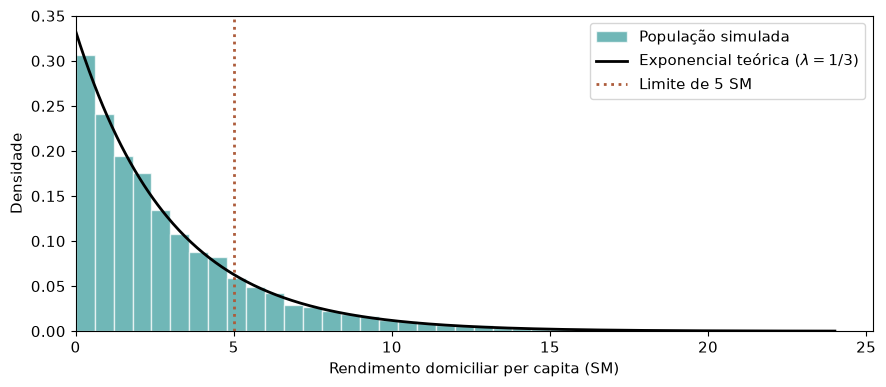

In [4]:
# Compara a distribuição da renda simulada com a densidade teórica.
eixo_r = np.linspace(0, renda.max(), 500)
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(renda, bins=40, density=True, color='#339999', edgecolor='#FFFFFF', alpha=.7, label='População simulada')
ax.plot(eixo_r, stats.expon.pdf(eixo_r, scale=3), color='#000000', linewidth=2, label=r'Exponencial teórica ($\lambda=1/3$)')
ax.axvline(5, color='#ad5c3b', linestyle=':', linewidth=2, label='Limite de 5 SM')
ax.set(xlabel='Rendimento domiciliar per capita (SM)', ylabel='Densidade')
ax.set_xlim(left=0)
ax.grid(False)
ax.legend()
fig.tight_layout()
plt.show()

**Figura 1 - Distribuição da renda simulada e densidade teórica.** As barras representam a densidade empírica das 10.000 rendas e a curva corresponde ao modelo Exponencial com taxa $\lambda=1/3$ usado na geração. A concentração em rendas baixas e a cauda alongada à direita acompanham a forma teórica. A linha pontilhada marca o limite de 5 SM, com as rendas inferiores à esquerda. Fonte: CARUBBI, 2026.

## 4. População, seleção da amostra e representatividade

### 4.1. Contexto

Uma pesquisa pretende estimar o rendimento domiciliar per capita médio das 10 mil pessoas da população simulada, consultando apenas 30 delas. A população reúne pessoas de diferentes classes de renda.

Como a escolha dos participantes pode afetar quais classes aparecem na amostra e a estimativa da média populacional?

### 4.2. Fundamentação teórica

O planejamento de um estudo estatístico exige delimitar o universo de interesse e estabelecer como serão selecionados os elementos a observar.

A **população** é o conjunto dos elementos que constituem o *universo do estudo* e podem ser observados sob as mesmas condições, conforme Barbetta, Reis e Bornia (2010). Quando finita, seu tamanho é representado por $N$. Uma **amostra** é uma *parte dessa população* selecionada para o estudo, com tamanho representado por $n$.

O *processo de seleção dos elementos* que compõem a amostra é denominado **amostragem**. Uma forma de realizar essa seleção é a **amostragem aleatória simples (AAS)**. Na modalidade sem reposição, selecionam-se aleatoriamente $n$ elementos de uma população finita, de modo que cada subconjunto de tamanho $n$ tenha a *mesma probabilidade de constituir a amostra*. Consequentemente, todos os elementos têm a mesma probabilidade de inclusão, conforme Barbetta, Reis e Bornia (2010).

<div style="text-align: center">
<img src="https://raw.githubusercontent.com/carubbi/MQ/main/notebooks/assets/imgs/u3_s01/barbetta_figura_7_1.png" alt="Figura 2 - População, amostragem e amostra. A amostragem seleciona elementos da população para compor a amostra. A seta de inferência indica o uso dos resultados amostrais para obter conclusões sobre a população. Fonte: Barbetta, Reis e Bornia (2010)." style="width: 760px; max-width: 100%; height: auto">
</div>

**Figura 2 - População, amostragem e amostra.** A amostragem seleciona elementos da população para compor a amostra. A seta de inferência indica o uso dos resultados amostrais para obter conclusões sobre a população. Fonte: Barbetta, Reis e Bornia (2010).

### 4.3. Aplicação

Considere a população gerada na seção 3. Compare duas amostras de 30 pessoas, uma formada pelas pessoas de menor renda e outra selecionada aleatoriamente sem reposição.

Observe quais classes de renda aparecem em cada amostra e compare suas rendas médias com a média da população. Explique como o procedimento de seleção contribuiu para os resultados observados.

#### 4.3.1. Implementação sem pacotes

A função <code>aas</code> seleciona índices a partir de números pseudoaleatórios uniformes entre 0 e 1. O parâmetro <code>rep</code> controla a reposição. Com <code>rep=False</code>, o índice selecionado é retirado da lista disponível. Com <code>rep=True</code>, ele permanece disponível e pode aparecer novamente, permitindo que o tamanho amostral supere o tamanho da população.

A função <code>menores</code> recebe uma lista de rendas e identifica os menores valores por comparação direta. A fonte de aleatoriedade é o gerador da biblioteca padrão <code>random</code> do Python.

A semente permite reproduzir os resultados de cada implementação. Como os algoritmos utilizam a sequência pseudoaleatória de maneiras diferentes, as amostras obtidas aqui podem diferir das apresentadas na implementação com pacotes.

In [5]:
# Define a AAS com ou sem reposição.
def aas(N, n, rng, rep):
    """Seleciona n índices com (rep=True) ou sem reposição (rep=False)."""
    if N < 0 or n < 0:
        raise ValueError("N e n devem ser não negativos.")
    if not rep and n > N:
        raise ValueError("Sem reposição, n deve ser menor ou igual a N.")
    if N == 0 and n > 0:
        raise ValueError("Uma amostra positiva exige uma população não vazia.")

    # Prepara os índices disponíveis.
    disp = list(range(N))
    idx = []

    # Seleciona uma posição e registra o índice correspondente.
    for _ in range(n):
        u = rng.random()
        pos = int(u * len(disp))
        idx.append(disp[pos])
        if not rep:
            disp.pop(pos)

    return idx

# Define a seleção dos menores valores de uma lista numérica.
def menores(val, n):
    """Retorna os n menores valores em ordem crescente."""
    if not 0 <= n <= len(val):
        raise ValueError("n deve estar entre 0 e o tamanho da lista.")

    # Prepara uma cópia dos valores disponíveis.
    disp = val.copy()
    am = []

    # Identifica e retira o menor valor disponível.
    for _ in range(n):
        pos_min = 0
        for pos in range(1, len(disp)):
            if disp[pos] < disp[pos_min]:
                pos_min = pos

        am.append(disp.pop(pos_min))

    return am

In [6]:
# Prepara as listas da população e o gerador da biblioteca padrão.
from random import Random

rendas = renda.tolist()
n_man = 30
rng_man = Random(44)

# Seleciona as menores rendas e uma amostra por AAS sem reposição.
rend_min = menores(rendas, n_man)
idx_man = aas(N, n_man, rng_man, rep=False)
rend_man = [rendas[i] for i in idx_man]
print('Média das menores rendas:', sum(rend_min) / n_man)
print('Média da amostra aleatória:', sum(rend_man) / n_man)

Média das menores rendas: 0.0043187022482340095
Média da amostra aleatória: 3.929523065207134


#### 4.3.2. Implementação com pacotes

A seleção das menores rendas usa <code>nsmallest</code> e as médias são calculadas com <code>mean</code> (PANDAS DEVELOPMENT TEAM, 2026). A seleção aleatória usa <code>Generator.choice</code>, com <code>replace=False</code> e semente 44 (NUMPY DEVELOPERS, 2026). As rotinas e o gráfico são fornecidos prontos.

Antes de executar, preveja como a escolha dos menores rendimentos afetará a média obtida.

In [7]:
# Seleciona as 30 pessoas de menor renda e apresenta as dez primeiras.
n_am = 30
am_min = pop.nsmallest(n_am, 'Renda (SM)').copy()
display(am_min.head(10).set_index('ID').rename(columns={'Renda (SM)': 'R (SM)'}))

,R (SM),Classe
ID,,
6967,0.000022,E
4061,0.000488,E
9246,0.000500,E
7346,0.000581,E
4518,0.000784,E
7297,0.001414,E
8458,0.001851,E
4104,0.001902,E
6892,0.001964,E


**Tabela 2 - Dez primeiros registros da seleção das menores rendas.** A amostra completa contém as 30 pessoas de menor renda, todas na classe E, com renda de até 2 SM. Esse critério exclui os demais perfis. **Legenda.** ID = identificador da pessoa. R = rendimento domiciliar per capita. SM = salário mínimo de referência. Fonte: CARUBBI, 2026.

In [8]:
# Seleciona 30 pessoas sem reposição e apresenta as dez primeiras.
rng_aas = np.random.default_rng(44)
idx_aas = rng_aas.choice(N, size=n_am, replace=False)
am_aas = pop.iloc[idx_aas].copy()
display(am_aas.head(10).set_index('ID').rename(columns={'Renda (SM)': 'R (SM)'}))

,R (SM),Classe
ID,,
4415,7.266929,C
5864,3.021045,D
9870,6.091559,C
5337,0.341344,E
9266,5.966886,C
4048,3.630220,D
4012,2.700461,D
883,0.133356,E
6770,2.976856,D


**Tabela 3 - Dez primeiros registros da amostra obtida por AAS.** A amostra completa contém 30 pessoas selecionadas sem reposição, com semente 44. O mecanismo dá a todos os subconjuntos de tamanho 30 a mesma probabilidade de seleção. **Legenda.** ID = identificador da pessoa. R = rendimento domiciliar per capita. SM = salário mínimo de referência. AAS = amostra aleatória simples. Fonte: CARUBBI, 2026.

In [9]:
# Compara as médias das duas amostras com a média populacional.
media_pop = renda.mean()
media_min = am_min['Renda (SM)'].mean()
media_aas = am_aas['Renda (SM)'].mean()
tab_renda = pd.DataFrame({
    'Conjunto': ['População', 'Menores rendas', 'Amostra por AAS'],
    'Pessoas': [N, n_am, n_am],
    'Renda média (SM)': [media_pop, media_min, media_aas],
    'Diferença (SM)': [0, media_min - media_pop, media_aas - media_pop],
})
display(tab_renda.set_index('Conjunto').rename(
    columns={'Pessoas': 'N/n', 'Renda média (SM)': 'M (SM)', 'Diferença (SM)': 'Dif (SM)'},
    index={'População': 'Pop.', 'Menores rendas': 'Men.', 'Amostra por AAS': 'AAS'},
).rename_axis('Conj.'))

,N/n,M (SM),Dif (SM)
Conj.,,,
Pop.,10000,2.999697,0.000000
Men.,30,0.004319,-2.995378
AAS,30,2.949245,-0.050452


**Tabela 4 - Rendas médias da população e das amostras.** A média populacional é aproximadamente 3,000 SM. A seleção das menores rendas produz uma média muito inferior. A diferença da amostra aleatória representa uma realização da variabilidade amostral. **Legenda.** Conj. = conjunto. Pop. = população. Men. = seleção das menores rendas. AAS = amostra aleatória simples. N/n = número de pessoas na população ou na amostra. M = renda média. Dif = diferença em relação à média populacional. SM = salário mínimo de referência. Fonte: CARUBBI, 2026.

In [10]:
# Compara a composição por classe de renda nos três conjuntos.
comp = pd.DataFrame({
    'População (p)': pop['Classe'].value_counts(normalize=True).reindex(classes, fill_value=0),
    'Menores rendas (p̂)': am_min['Classe'].value_counts(normalize=True).reindex(classes, fill_value=0),
    'Amostra por AAS (p̂)': am_aas['Classe'].value_counts(normalize=True).reindex(classes, fill_value=0),
})
comp.index.name = 'Classe'
display(comp.rename(columns={
    'População (p)': 'Pop. (p)',
    'Menores rendas (p̂)': 'Men. (p̂)',
    'Amostra por AAS (p̂)': 'AAS (p̂)',
}))

,Pop. (p),Men. (p̂),AAS (p̂)
Classe,,,
A,0.000700,0.000000,0.000000
B,0.035400,0.000000,0.000000
C,0.231400,0.000000,0.333333
D,0.249000,0.000000,0.233333
E,0.483500,1.000000,0.433333


**Tabela 5 - Composição por classe de renda.** A seleção dos menores rendimentos concentra 100% das pessoas na classe E, com renda de até 2 SM. A composição da amostra aleatória pode diferir da composição populacional. **Legenda.** Pop. = população. Men. = seleção das menores rendas. AAS = amostra aleatória simples. p = proporção populacional em cada classe. p̂ = proporção amostral em cada classe. SM = salário mínimo de referência. Fonte: CARUBBI, 2026.

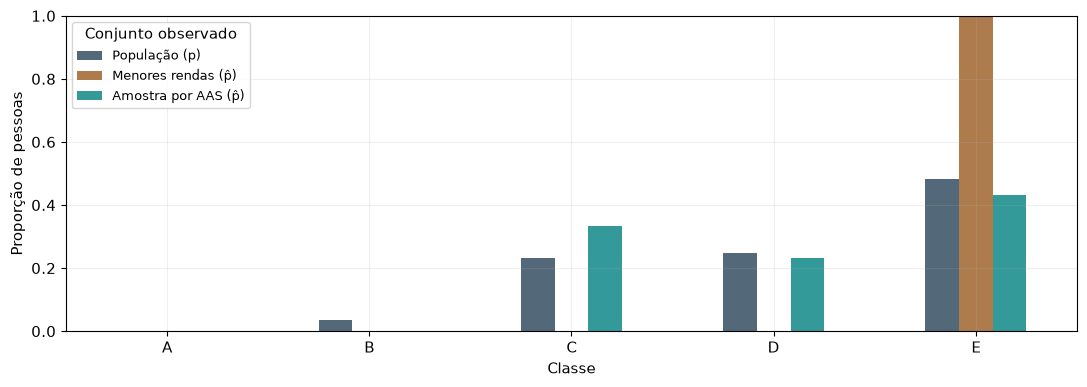

In [11]:
# Compara graficamente a composição dos três conjuntos.
ax = comp.plot.bar(rot=0, color=['#536878', '#ad7b4c', '#339999'], figsize=(11, 4))
ax.set(xlabel='Classe', ylabel='Proporção de pessoas', ylim=(0, 1))
ax.legend(title='Conjunto observado', fontsize=9)
plt.tight_layout()
plt.show()

**Figura 3 - Composição da população e das amostras por classe de renda.** A seleção das menores rendas inclui apenas a classe E e exclui as classes A, B, C e D. A seleção aleatória permite a participação de todos os perfis, sem garantir que cada amostra reproduza suas proporções populacionais. Fonte: CARUBBI, 2026.

#### 4.3.3. Interpretação

A seleção das 30 menores rendas reuniu apenas pessoas da classe E e subestimou a média populacional.

Na AAS sem reposição, cada pessoa tinha 0,3% de *probabilidade de integrar a amostra completa*. Entre as pessoas ainda disponíveis, a probabilidade de seleção aumenta a cada etapa.

A média e a composição da amostra obtida por AAS podem diferir das populacionais pela *variação natural entre seleções*.

## 5. Parâmetros, estatísticas e variabilidade entre amostras

### 5.1. Contexto

Na mesma pesquisa, duas amostras independentes de tamanho 30 podem produzir valores diferentes para a média e a variância do rendimento domiciliar per capita e para a proporção de pessoas com renda abaixo de 5 SM.

Como distinguir as características numéricas da população dos resultados obtidos em cada amostra? Por que esses resultados podem variar mesmo quando a população é a mesma?

Compreender essas diferenças ajuda a avaliar o alcance das conclusões obtidas a partir de uma única amostra.

### 5.2. Fundamentação teórica

Um **parâmetro** é uma *característica numérica da população*. Para a população e a variável consideradas, seu valor é *fixo, mesmo quando desconhecido*. Em uma população finita, a média, a variância e a proporção são

$$
\mu=\frac{1}{N}\sum_{i=1}^{N}x_i,\qquad
\sigma^2=\frac{1}{N}\sum_{i=1}^{N}(x_i-\mu)^2,\qquad
p=\frac{1}{N}\sum_{i=1}^{N}a_i.
\tag{1.1}
$$

$N$ é o tamanho da população, $x_i$ é o valor observado na unidade $i$, $\mu$ é a média populacional e $\sigma^2$ é a variância populacional. $a_i$ vale 1 quando a unidade apresenta o atributo e 0 caso contrário. $p$ é a proporção populacional. A média tem a unidade de $x_i$, a variância tem essa unidade ao quadrado e a proporção é adimensional.

Uma **estatística** é uma *quantidade calculada com os dados da amostra*, sem depender de parâmetros desconhecidos. Na amostragem aleatória, seu valor pode variar entre amostras. Antes da seleção aleatória da amostra, a média amostral $\bar X$ e a proporção amostral $\widehat P$ são *variáveis aleatórias*. Após a observação, $\bar x$ e $\hat p$ representam os respectivos *valores observados*. Os resumos amostrais são

$$
\bar x=\frac{1}{n}\sum_{i=1}^{n}x_i,\qquad
s^2=\frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar x)^2,\qquad
\hat p=\frac{1}{n}\sum_{i=1}^{n}a_i.
\tag{1.2}
$$

$n$ é o tamanho da amostra, $\bar x$ é a média amostral, $s^2$ é a variância amostral e $\hat p$ é a proporção amostral observada. A média e a proporção podem ser calculadas para $n\geq 1$. A variância amostral exige $n>1$. O desvio-padrão amostral é $s=\sqrt{s^2}$.

Usamos $n-1$ na definição da variância amostral $s^2$. Para observações independentes de uma mesma distribuição, com variância finita $\sigma^2$, a variância amostral $s^2$ estima a variância da distribuição $\sigma^2$ *sem viés*, ou seja, seu valor esperado é igual a $\sigma^2$. Nos cálculos da população completa, usamos o tamanho da população $N$ como denominador da variância populacional $\sigma^2$.

### 5.3. Aplicação

Selecione duas amostras independentes de 30 pessoas, com reposição. Calcule a média e a variância da renda e a proporção de pessoas com renda abaixo de 5 SM em cada amostra e na população.

Compare os resultados e classifique cada medida como parâmetro ou valor observado de uma estatística.

#### 5.3.1. Implementação com pacotes

<code>np.mean</code> calcula a média dos valores. Para indicadores com valores 0 e 1, essa média corresponde à proporção do atributo de interesse. <code>np.var</code> calcula a variância populacional com <code>ddof=0</code> e a variância amostral com <code>ddof=1</code>. [Documentação de var](https://numpy.org/doc/2.5/reference/generated/numpy.var.html) (NUMPY DEVELOPERS, 2026).

In [12]:
# Calcula os parâmetros da população finita e seleciona duas amostras.
mu = renda.mean()
sigma2 = renda.var(ddof=0)
sigma = math.sqrt(sigma2)
p = renda_menor5.mean()
rng_ab = np.random.default_rng(45)
am_a = rng_ab.choice(N, size=30, replace=True)
am_b = rng_ab.choice(N, size=30, replace=True)

In [13]:
# Compara parâmetros populacionais e estatísticas das duas amostras.
tab_par = []
for nome, idx, gl in [('População', np.arange(N), 0), ('Amostra A', am_a, 1), ('Amostra B', am_b, 1)]:
    tab_par.append({
        'Conjunto': nome,
        'Média (SM)': renda[idx].mean(),
        'Variância (SM²)': renda[idx].var(ddof=gl),
        'Proporção < 5 SM': renda_menor5[idx].mean(),
    })
display(pd.DataFrame(tab_par).set_index('Conjunto').rename(
    columns={'Média (SM)': 'M (SM)', 'Variância (SM²)': 'Var (SM²)', 'Proporção < 5 SM': 'Prop (< 5 SM)'},
    index={'População': 'Pop.', 'Amostra A': 'Am. A', 'Amostra B': 'Am. B'},
).rename_axis('Conj.'))

,M (SM),Var (SM²),Prop (< 5 SM)
Conj.,,,
Pop.,2.999697,8.730491,0.812900
Am. A,2.413059,6.164104,0.866667
Am. B,2.227549,4.608452,0.900000


**Tabela 6 - Parâmetros populacionais e estatísticas de duas amostras.** A população tem média de aproximadamente 3,000 SM, variância de 8,730 SM² e proporção de 81,29% com renda abaixo de 5 SM. As estatísticas variam com os registros selecionados. **Legenda.** Conj. = conjunto. Pop. = população. Am. A e Am. B = amostras A e B. M = renda média. Var = variância das rendas. Prop (< 5 SM) = proporção de pessoas com renda abaixo de 5 salários mínimos de referência. A variância populacional usa N e a amostral usa n−1 no denominador. Fonte: CARUBBI, 2026.

#### 5.3.2. Interpretação

Os valores calculados com os 10 mil registros são *parâmetros populacionais*. A média da renda é aproximadamente 3 SM.

As médias de 2,413 SM e 2,228 SM das amostras A e B são *valores observados de estatísticas amostrais*. As diferenças entre suas médias, variâncias e proporções ilustram a *variabilidade amostral*, mesmo com amostras de igual tamanho e selecionadas pelo mesmo procedimento.

## 6. Distribuições amostrais da proporção e da média

### 6.1. Contexto

Se a pesquisa fosse repetida muitas vezes, mantendo o tamanho amostral e o procedimento de seleção, obteríamos diferentes proporções de pessoas com renda abaixo de 5 SM e diferentes médias do rendimento domiciliar per capita.

Quais resultados apareceriam com maior frequência? Em torno de quais valores eles se concentrariam e quanto variariam entre amostras?

Compreender essa variação permite avaliar a precisão das estimativas sobre a população obtidas a partir de amostras.

### 6.2. Fundamentação teórica

A **distribuição amostral** é a *distribuição teórica de probabilidades de uma estatística*, considerando as amostras possíveis de mesmo tamanho, selecionadas pelo mesmo procedimento (BARBETTA; REIS; BORNIA, 2010). A *distribuição dos dados de uma amostra* descreve os valores individuais observados nessa amostra e suas frequências (MORETTIN; BUSSAB, 2010).

<div style="text-align: center">
<img src="https://raw.githubusercontent.com/carubbi/MQ/main/notebooks/assets/imgs/u3_s01/morettin_figura_10_1.png" alt="Figura 4 - Inferência e formação da distribuição amostral. O painel (a) relaciona uma amostra ao parâmetro populacional. O painel (b) mostra diferentes amostras, suas estatísticas e a formação da distribuição amostral. Fonte: Morettin e Bussab (2010)." style="width: 760px; max-width: 100%; height: auto">
</div>

**Figura 4 - Inferência e formação da distribuição amostral.** Em (a), o valor $t_0$ da estatística calculada na amostra é usado para inferir o parâmetro populacional $\theta$. Em (b), cada amostra fornece um valor $t_i$ da estatística $T$. A distribuição desses valores constitui a distribuição amostral de $T$. O símbolo $X$ representa a variável populacional, e $f$ e $g$ representam, respectivamente, as distribuições de $X$ e de $T$. Fonte: Morettin e Bussab (2010), Figura 10.1, p. 273.

Na AAS com reposição, os valores observados são *independentes e identicamente distribuídos (iid)*. Independentes porque o resultado de uma seleção não altera as probabilidades das demais. Identicamente distribuídos porque, em todas as seleções, a variável observada tem a mesma distribuição de probabilidades.

Em cada seleção, cada elemento da população tem probabilidade $1/N$ de ser selecionado. Para uma população de tamanho $N$ e uma amostra de tamanho $n$, existem $N^n$ *sequências ordenadas equiprováveis*.

Para uma população finita de tamanho $N$, sob AAS com reposição, a probabilidade de a estatística $T$ assumir o valor $t$ é

$$
\mathbb P(T=t)
=\frac{1}{N^n}+\cdots+\frac{1}{N^n}
=\frac{k_t}{N^n}.
\tag{1.3}
$$

$k_t$ é a quantidade de sequências que produzem o valor $t$. Diferentes sequências podem produzir o mesmo valor da estatística, e suas probabilidades são somadas para obter a probabilidade desse resultado.

Na simulação, repetimos $B$ vezes a seleção de uma amostra de tamanho $n$ da população conhecida, pelo mesmo procedimento, calculando a estatística em cada repetição. Seus valores e *frequências relativas* formam a *distribuição empírica*, que aproxima a forma e as probabilidades da distribuição amostral.

O *desvio-padrão dos dados* descreve a dispersão dos valores individuais. O **erro-padrão** é o *desvio-padrão da distribuição amostral de uma estatística* e expressa sua variabilidade entre amostras de mesmo tamanho, selecionadas pelo mesmo procedimento. Sua unidade é a mesma da estatística.

#### 6.2.1. Distribuição amostral da proporção

A **distribuição amostral da proporção** descreve os valores possíveis de $\widehat P$ e suas probabilidades sob o procedimento de seleção.

Na AAS com reposição, as variáveis $A_i$ de Bernoulli são iid, com probabilidade de sucesso $p$. A contagem de sucessos segue uma Binomial com parâmetros $n$ e $p$. A **proporção amostral** é essa contagem dividida por $n$, equivalente a uma *média de zeros e uns*. Suas propriedades são

$$
\widehat P=\frac{1}{n}\sum_{i=1}^{n}A_i,\qquad
\mathbb E[\widehat P]=p.
\tag{1.4}
$$

Na *AAS com reposição*, a variância e o erro-padrão são

$$
\operatorname{Var}(\widehat P)=\frac{p(1-p)}{n},\qquad
\operatorname{EP}(\widehat P)=\sqrt{\frac{p(1-p)}{n}}.
\tag{1.5}
$$

Na *AAS sem reposição*, as observações são dependentes. Para uma população finita de tamanho $N>1$ e $1\leq n\leq N$, multiplicamos a variância pelo fator de *correção para população finita* $(N-n)/(N-1)$ e o erro-padrão pela raiz quadrada desse fator (BARBETTA; REIS; BORNIA, 2010). Assim, temos

$$
\operatorname{Var}(\widehat P)=\frac{p(1-p)}{n}\frac{N-n}{N-1},\qquad
\operatorname{EP}(\widehat P)=\sqrt{\frac{p(1-p)}{n}\frac{N-n}{N-1}}.
\tag{1.6}
$$

$A_i$ é a variável aleatória que indica se a $i$-ésima unidade da amostra apresenta o atributo, com valor 1 para presença e 0 para ausência. $\widehat P$ é a proporção amostral aleatória, $p$ é o parâmetro populacional e $n$ é o tamanho amostral. Essas quantidades são adimensionais.

Quando $N$ é muito maior que $n$, o fator $(N-n)/(N-1)$ se aproxima de 1. Podemos então usar aproximadamente as variâncias e os erros-padrão da AAS com reposição. Como orientação prática, a correção costuma ser desprezada quando $n/N\leq 0{,}05$, ou seja, quando a amostra representa até 5% da população (BARBETTA; REIS; BORNIA, 2010).

Por exemplo, em uma pesquisa sobre renda, amostras diferentes podem apresentar proporções diferentes de pessoas com renda abaixo de 5 SM. Pelo mesmo procedimento de seleção, amostras maiores tendem a produzir proporções mais próximas da proporção populacional, pois seu erro-padrão é menor.

#### 6.2.2. Distribuição amostral da média

A **distribuição amostral da média** descreve os valores possíveis de $\bar X$ e suas probabilidades sob o procedimento de seleção. Considere uma população com média $\mu$ e *variância finita* $\sigma^2$. As propriedades da média amostral são

$$
\bar X=\frac{1}{n}\sum_{i=1}^{n}X_i,\qquad
\mathbb E[\bar X]=\mu.
\tag{1.7}
$$

Na *AAS com reposição*, as observações são iid e a variância e o erro-padrão são

$$
\operatorname{Var}(\bar X)=\frac{\sigma^2}{n},\qquad
\operatorname{EP}(\bar X)=\frac{\sigma}{\sqrt n}.
\tag{1.8}
$$

Na *AAS sem reposição* de uma população finita, essas expressões são

$$
\operatorname{Var}(\bar X)=\frac{\sigma^2}{n}\frac{N-n}{N-1},\qquad
\operatorname{EP}(\bar X)=\frac{\sigma}{\sqrt n}\sqrt{\frac{N-n}{N-1}}.
\tag{1.9}
$$

$X_i$ é a variável aleatória que representa a $i$-ésima observação da amostra. $n$ é o tamanho da amostra e $\bar X$ é a média amostral aleatória. O desvio-padrão populacional é $\sigma=\sqrt{\sigma^2}$. O erro-padrão da média tem a mesma unidade de $X_i$.

Por exemplo, uma renda muito elevada pode alterar bastante a média de uma amostra pequena. Em amostras maiores, cada observação tem menor peso no cálculo, e as médias tendem a variar menos entre seleções. Essa redução da variabilidade corresponde à diminuição do erro-padrão da média.

### 6.3. Aplicação

Retome a população simulada de 10 mil pessoas, com renda mensal domiciliar per capita expressa em salários mínimos (SM). Gere $B=10\,000$ amostras independentes de tamanho $n=2$, com reposição. Em cada amostra, calcule a proporção de pessoas com renda abaixo de 5 SM e a renda média.

A reposição mantém todas as pessoas disponíveis em cada extração. Uma pessoa pode aparecer mais de uma vez na mesma amostra. Esse mecanismo difere da seleção sem reposição usada na seção 4.

#### 6.3.1. Implementação sem pacotes

In [14]:
# Define a variância da média com ou sem reposição.
def var_med(var, n, N, rep):
    """Calcula a variância da média usando a variância populacional."""
    if var < 0 or n <= 0 or N <= 0:
        raise ValueError("var deve ser não negativa e N e n devem ser positivos.")
    if not rep and (N <= 1 or n > N):
        raise ValueError("Sem reposição, exigir N > 1 e n <= N.")

    # Aplica a correção para população finita na seleção sem reposição.
    fc = 1 if rep else (N - n) / (N - 1)
    return var / n * fc

# Define o erro-padrão da média com ou sem reposição.
def ep_med(dp, n, N, rep):
    """Calcula a raiz da variância da média."""
    if dp < 0:
        raise ValueError("dp deve ser não negativo.")
    return math.sqrt(var_med(dp ** 2, n, N, rep=rep))

# Define o erro-padrão da proporção com ou sem reposição.
def ep_prop(p, n, N, rep):
    """Usa a variância Bernoulli p(1-p) no cálculo do erro-padrão."""
    if not 0 <= p <= 1:
        raise ValueError("p deve estar entre 0 e 1.")
    return math.sqrt(var_med(p * (1 - p), n, N, rep=rep))

#### 6.3.2. Implementação com pacotes

Cada linha da matriz contém os índices de uma amostra. A média dos indicadores 0 e 1 produz uma proporção amostral. A média da renda por linha produz uma média amostral. Usaremos semente 46.

In [15]:
# Gera amostras com reposição e calcula as duas estatísticas por linha.
B = 10_000
n_dist = 2
rng_dist = np.random.default_rng(46)
idx_dist = rng_dist.choice(N, size=(B, n_dist), replace=True)
prop_2 = renda_menor5[idx_dist].mean(axis=1)
med_2 = renda[idx_dist].mean(axis=1)

# Mostra os valores individuais e as estatísticas das primeiras dez amostras.
display(pd.DataFrame({
    'ID': idx_dist[:10, 0] + 1,
    'R1': renda[idx_dist[:10, 0]],
    'A1': renda_menor5[idx_dist[:10, 0]],
    'ID2': idx_dist[:10, 1] + 1,
    'R2': renda[idx_dist[:10, 1]],
    'A2': renda_menor5[idx_dist[:10, 1]],
    'P': prop_2[:10],
    'M': med_2[:10],
}, index=pd.RangeIndex(1, 11, name='Rep.')).round(3))

,ID,R1,A1,ID2,R2,A2,P,M
Rep.,,,,,,,,
1,5027,1.789000,1,9057,8.222000,0,0.500000,5.006000
2,2194,2.716000,1,773,2.581000,1,1.000000,2.648000
3,5493,0.293000,1,2726,3.894000,1,1.000000,2.094000
4,2490,0.369000,1,6219,1.848000,1,1.000000,1.109000
5,1378,0.276000,1,9341,1.086000,1,1.000000,0.681000
6,8024,2.300000,1,850,0.971000,1,1.000000,1.636000
7,7664,1.232000,1,6293,0.645000,1,1.000000,0.939000
8,8086,2.423000,1,7756,4.553000,1,1.000000,3.488000
9,2347,3.191000,1,5115,0.608000,1,1.000000,1.900000


**Tabela 7 - Primeiras dez amostras da simulação.** Cada linha apresenta duas pessoas selecionadas com reposição e as estatísticas da dupla. Valores arredondados a três casas decimais. **Legenda.** Rep. = repetição da simulação. ID e ID2 = identificadores da primeira e da segunda pessoa selecionadas. R1 e R2 = suas rendas em salários mínimos de referência (SM). A1 e A2 = 1 quando a renda correspondente é inferior a 5 SM e 0 caso contrário. P = proporção amostral de rendas abaixo de 5 SM. M = renda média da dupla. Fonte: simulação própria, adaptada de Pinheiro et al. (2009).

In [16]:
# Compara os momentos teóricos e simulados das duas estatísticas.
tab_dist = pd.DataFrame({
    'Estat.': ['P', 'M'],
    'Et': [p, mu],
    'Ms': [prop_2.mean(), med_2.mean()],
    'Vart': [p * (1-p) / n_dist, var_med(sigma2, n_dist, N, rep=True)],
    'Vars': [prop_2.var(ddof=1), med_2.var(ddof=1)],
    'EPt': [ep_prop(p, n_dist, N, rep=True), ep_med(sigma, n_dist, N, rep=True)],
    'EPs': [prop_2.std(ddof=1), med_2.std(ddof=1)],
})
display(tab_dist.set_index('Estat.'))

,Et,Ms,Vart,Vars,EPt,EPs
Estat.,,,,,,
P,0.812900,0.814450,0.076047,0.075504,0.275766,0.274779
M,2.999697,2.999980,4.365246,4.360125,2.089317,2.088091


**Tabela 8 - Momentos teóricos e simulados das distribuições amostrais.** Os centros simulados se aproximam dos parâmetros da população. Com $n=2$, a variância teórica da média é metade da variância das rendas individuais, pois $\operatorname{Var}(\bar X)=\sigma^2/n$ para observações independentes. Para P, as medidas são adimensionais. **Legenda.** Estat. = estatística. P = proporção amostral de pessoas com renda abaixo de 5 SM. M = renda média amostral. Et = esperança teórica. Ms = média simulada. Vart = variância teórica. Vars = variância simulada. EPt = erro-padrão teórico. EPs = erro-padrão simulado. Para M, Et, Ms, EPt e EPs estão em salários mínimos de referência (SM), e Vart e Vars em SM². Fonte: CARUBBI, 2026.

In [17]:
# Compara a frequência simulada da proporção com a distribuição Binomial exata.
k_dist = np.arange(n_dist + 1)
freq = pd.Series(prop_2).value_counts(normalize=True).reindex(k_dist / n_dist, fill_value=0)
tab_prop = pd.DataFrame({
    'k': k_dist,
    'P': k_dist / n_dist,
    'Pe': stats.binom.pmf(k_dist, n_dist, p),
    'Fs': freq.to_numpy(),
})
display(tab_prop)

,k,P,Pe,Fs
0,0,0.000000,0.035006,0.034300
1,1,0.500000,0.304187,0.302500
2,2,1.000000,0.660806,0.663200


**Tabela 9 - Distribuição da proporção amostral para n = 2.** As proporções possíveis são 0, 0,5 e 1. A probabilidade de não observar pessoas com renda abaixo de 5 SM é positiva, embora esse grupo exista na população. As frequências simuladas aproximam as probabilidades exatas. **Legenda.** k = número de pessoas da amostra com renda abaixo de 5 salários mínimos de referência (SM). P = proporção amostral, calculada por $k/n$. Pe = probabilidade exata de cada valor de P. Fs = frequência relativa de cada valor de P nas $B$ repetições da simulação. n = tamanho de cada amostra. Fonte: CARUBBI, 2026.

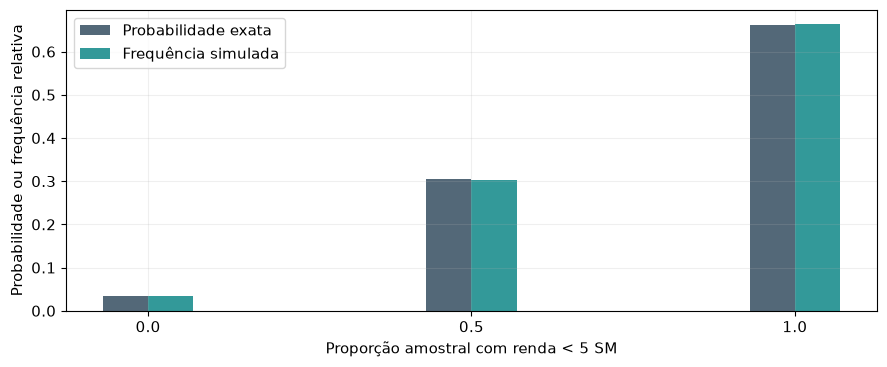

In [18]:
# Representa as probabilidades exatas e as frequências simuladas das proporções.
fig, ax = plt.subplots()
ax.bar(k_dist / n_dist - .035, tab_prop['Pe'], width=.07, label='Probabilidade exata', color='#536878')
ax.bar(k_dist / n_dist + .035, tab_prop['Fs'], width=.07, label='Frequência simulada', color='#339999')
ax.set(xticks=k_dist / n_dist, xlabel='Proporção amostral com renda < 5 SM', ylabel='Probabilidade ou frequência relativa')
ax.legend()
fig.tight_layout()
plt.show()

**Figura 5 - Distribuição da proporção amostral com n = 2.** As frequências de Monte Carlo se aproximam das probabilidades da Binomial. A proporção 1 é o resultado mais provável nesse tamanho amostral. Ela ocorre quando as duas pessoas selecionadas têm renda abaixo de 5 SM. Fonte: CARUBBI, 2026.

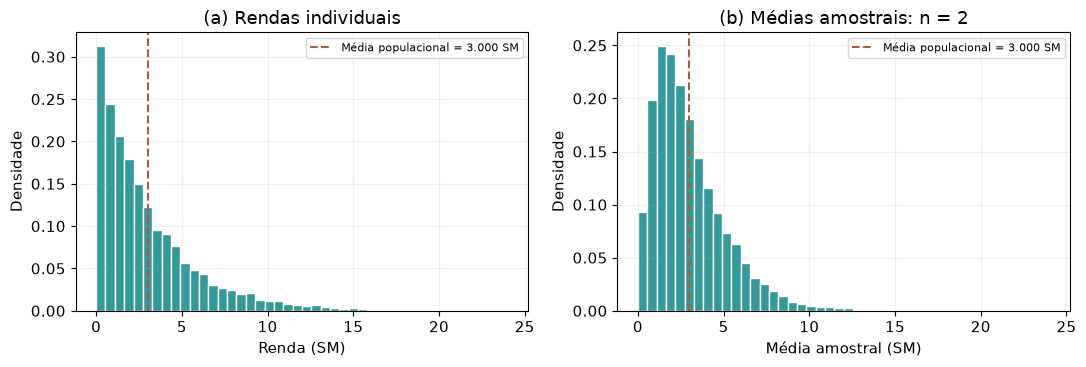

In [19]:
# Compara a população com as médias de amostras de duas pessoas.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
lim = max(renda.max(), med_2.max())
bins = np.linspace(0, lim, 45)
for ax, val, titulo in zip(axes, [renda, med_2], ['(a) Rendas individuais', '(b) Médias amostrais: n = 2']):
    ax.hist(val, bins=bins, density=True, color='#339999', edgecolor='white')
    ax.axvline(mu, color='#ad5c3b', linestyle='--', label=f'Média populacional = {mu:.3f} SM')
    ax.set(title=titulo, xlabel='Renda (SM)' if ax is axes[0] else 'Média amostral (SM)', ylabel='Densidade')
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

**Figura 6 - Rendas individuais e distribuição simulada da média amostral para n = 2.** Em (a), as rendas individuais apresentam forte assimetria à direita. Em (b), cada média amostral é calculada com apenas $n=2$ pessoas, e a distribuição dessas médias ainda apresenta assimetria. Seu centro permanece próximo de 3,000 SM, com menor dispersão e variância teórica de aproximadamente 4,365 SM². Fonte: elaboração didática sobre a população simulada, inspirada na comparação de Barbetta, Reis e Bornia (2010).

#### 6.3.3. Interpretação

A distribuição das rendas descreve diferenças entre pessoas. As distribuições amostrais da proporção e da média descrevem diferenças entre resultados de amostras. Cada repetição contribui com uma proporção amostral e uma média amostral.

A proporção de pessoas com renda abaixo de 5 SM e a renda média da população são os centros teóricos das respectivas distribuições amostrais. Para $n=2$, a proporção amostral só pode assumir três valores. A média amostral tem muitos valores possíveis e sua representação por histograma é uma aproximação por classes.

Aumentar $B$ melhora a aproximação de Monte Carlo para esse $n$. Para reduzir a dispersão das estatísticas, precisamos aumentar o tamanho de cada amostra sob o mecanismo especificado.

## 7. Teorema Central do Limite (TCL)

### 7.1. Contexto

Uma pesquisa pretende estimar o rendimento domiciliar per capita médio de uma população a partir de uma amostra. A população apresenta muitas rendas baixas e poucas rendas elevadas, caracterizando uma distribuição assimétrica à direita (PINHEIRO et al., 2009).

Amostras diferentes podem produzir médias diferentes. Como o tamanho da amostra afeta a variação dessas médias e a forma de sua distribuição?

Essa análise permite avaliar quando a distribuição Normal pode ser usada para calcular probabilidades relativas às médias amostrais.

### 7.2. Fundamentação teórica

Considere observações *independentes e identicamente distribuídas*, com média $\mu$ e *variância finita* $\sigma^2>0$. Se a população é Normal, $X\sim\mathcal{N}(\mu,\sigma^2)$, a média amostral também tem distribuição Normal. Para uma população com outra forma, o **Teorema Central do Limite (TCL)** estabelece

$$
Z_n=\frac{\bar X-\mu}{\sigma/\sqrt n}
\ \xrightarrow[n\to\infty]{\mathcal D}\ \mathcal N(0,1).
\tag{1.10}
$$

$Z_n$ é a média amostral padronizada, e a seta indica *convergência em distribuição*. A aproximação para um tamanho amostral particular depende da população e da precisão desejada. A aproximação pela Normal melhora conforme o tamanho amostral aumenta. Populações muito assimétricas podem exigir amostras maiores para que essa aproximação seja adequada. O TCL estabelece a convergência da *distribuição da média amostral padronizada* para a Normal padrão, conforme Morettin e Bussab (2010).

A referência Normal pode aproximar a distribuição amostral da proporção quando há *números esperados de sucessos e fracassos suficientemente grandes*. O tamanho total da amostra, isoladamente, é insuficiente para avaliar essa aproximação, conforme Barbetta, Reis e Bornia (2010).

<div style="position: relative; max-width: 800px; margin: 0 auto; padding-left: 28px; box-sizing: border-box">
<span style="position: absolute; left: 0; top: 12%">(a)</span>
<span style="position: absolute; left: 0; top: 37%">(b)</span>
<span style="position: absolute; left: 0; top: 62%">(c)</span>
<span style="position: absolute; left: 0; top: 87%">(d)</span>
<img src="https://raw.githubusercontent.com/carubbi/MQ/main/notebooks/assets/imgs/u3_s01/morettin_figura_10_5.png" alt="Figura 7 - Quatro painéis em linhas. (a) População uniforme. (b) População decrescente. (c) População unimodal assimétrica. (d) População bimodal. Em cada linha, as distribuições das médias se aproximam da Normal conforme n aumenta. Fonte: Morettin e Bussab (2010)." style="display: block; width: 100%; height: auto">
</div>

**Figura 7 - Formas populacionais e distribuições amostrais da média.** Cada painel corresponde a uma linha, com a população à esquerda e as distribuições das médias à direita. Em (a), a população uniforme produz médias com forma progressivamente mais próxima da Normal para $n=2$, 5 e 25. Em (b), a assimetria da população decrescente ainda aparece nas médias para $n=2$ e diminui para $n=10$ e 30. Em (c), a população unimodal assimétrica produz médias mais simétricas para $n=3$, 5 e 10. Em (d), as duas concentrações da população bimodal dão lugar a uma forma aproximadamente Normal nas médias para $n=5$, 15 e 25. Fonte: Morettin e Bussab (2010).

### 7.3. Aplicação

Use as funções de 6.3.1 para calcular a variância e o erro-padrão da média para um tamanho amostral fornecido. Em seguida, confronte sua previsão com as 10.000 médias geradas para cada tamanho amostral.

#### 7.3.1. Implementação sem pacotes

In [20]:
# Aplica as propriedades à população finita de rendas.
n_ex = 30
print(f'Variância da média para n={n_ex}: {var_med(sigma2, n_ex, N, rep=True):.6f} SM²')
print(f'Erro-padrão para n={n_ex}: {ep_med(sigma, n_ex, N, rep=True):.6f} SM')

Variância da média para n=30: 0.291016 SM²
Erro-padrão para n=30: 0.539459 SM


#### 7.3.2. Implementação com pacotes

Simularemos novas médias amostrais para todos os tamanhos, incluindo $n=2$, com semente 48. Cada linha da matriz é uma amostra com reposição. Os gráficos e a tabela são fornecidos prontos.

In [21]:
# Simula novas médias amostrais para cada tamanho, com semente registrada.
rng_med = np.random.default_rng(48)
tam = [1, 2, 30, 400]
med_sim = {}
resumos = []
for n in tam:
    med_sim[n] = rng_med.choice(renda, size=(B, n), replace=True).mean(axis=1)
    medias = med_sim[n]
    resumos.append({
        'n': n,
        'Média teórica': mu,
        'Média simulada': medias.mean(),
        'Variância teórica': var_med(sigma2, n, N, rep=True),
        'Variância simulada': medias.var(ddof=1),
        'EP teórico': ep_med(sigma, n, N, rep=True),
        'EP simulado': medias.std(ddof=1),
    })
display(pd.DataFrame(resumos).set_index('n').rename(columns={
    'Média teórica': 'Et', 'Média simulada': 'Ms',
    'Variância teórica': 'Vart', 'Variância simulada': 'Vars',
    'EP teórico': 'EPt', 'EP simulado': 'EPs',
}))

,Et,Ms,Vart,Vars,EPt,EPs
n,,,,,,
1,2.999697,3.077246,8.730491,9.002394,2.954740,3.000399
2,2.999697,2.962540,4.365246,4.191371,2.089317,2.047284
30,2.999697,3.006644,0.291016,0.289508,0.539459,0.538059
400,2.999697,3.001807,0.021826,0.021868,0.147737,0.147879


**Tabela 10 - Momentos teóricos e simulados da média amostral.** Os centros simulados permanecem próximos da média populacional. Conforme $n$ aumenta, a variância e o erro-padrão da média amostral diminuem, indicando maior concentração das médias amostrais em torno desse valor. **Legenda.** n = tamanho amostral. Et = esperança teórica. Ms = média simulada. Vart = variância teórica. Vars = variância simulada. EPt = erro-padrão teórico. EPs = erro-padrão simulado. Et, Ms, EPt e EPs estão em salários mínimos de referência (SM), e Vart e Vars em SM². Fonte: CARUBBI, 2026.

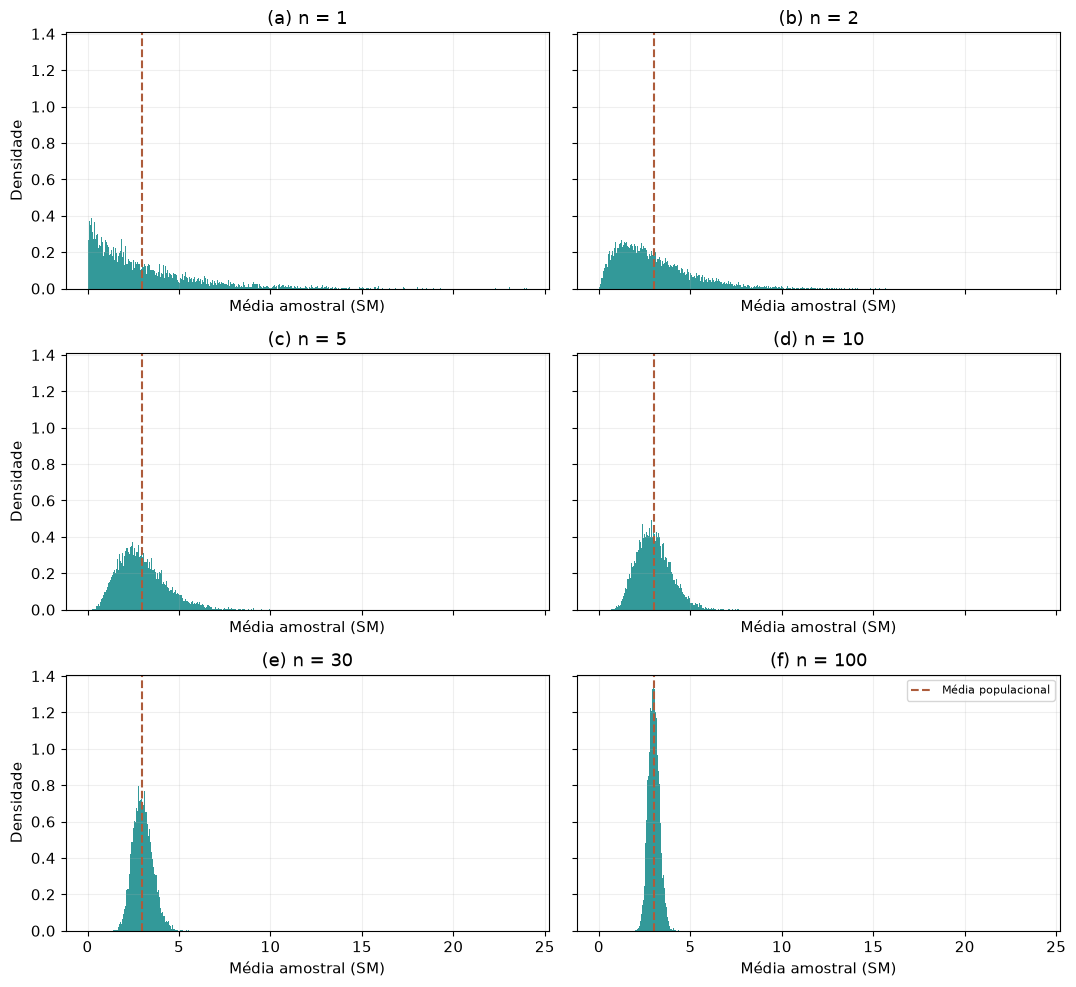

In [22]:
# Simula médias amostrais para os seis tamanhos do painel, com semente registrada.
tam_fig = [1, 2, 5, 10, 30, 100]
rng_fig = np.random.default_rng(49)
med_fig = {}
for n in tam_fig:
    med_fig[n] = rng_fig.choice(renda, size=(B, n), replace=True).mean(axis=1)

# Mostra a concentração das médias em uma escala comum, cobrindo todos os resultados.
fig, axes = plt.subplots(3, 2, figsize=(11, 10), sharex=True, sharey=True)
axes = axes.ravel()
lim = max(val.max() for val in med_fig.values())
bins = np.linspace(0, lim, 501)
for ax, n, letra in zip(axes, tam_fig, 'abcdef'):
    ax.hist(med_fig[n], bins=bins, density=True, color='#339999', linewidth=0)
    ax.axvline(mu, color='#ad5c3b', linestyle='--', label='Média populacional')
    ax.set(title=f'({letra}) n = {n}', xlabel='Média amostral (SM)')
for ax in axes[::2]:
    ax.set_ylabel('Densidade')
axes[-1].legend(fontsize=8)
fig.tight_layout()
plt.show()

**Figura 8 - Distribuições amostrais da média na escala original.** Em (a), $n=1$ reproduz a distribuição assimétrica das rendas individuais. Em (b), $n=2$ reduz a dispersão, mas mantém forte assimetria à direita. Em (c), $n=5$ evidencia a transição para uma forma mais simétrica. Em (d), $n=10$ apresenta assimetria menos acentuada. Em (e), $n=30$ aproxima a forma da distribuição amostral da média da Normal. Em (f), $n=100$ apresenta a maior concentração em torno da média populacional e menor assimetria. Cada painel reúne 10.000 médias simuladas com reposição e semente 49. Os painéis usam os mesmos limites e classes para permitir a comparação. Fonte: CARUBBI, 2026.

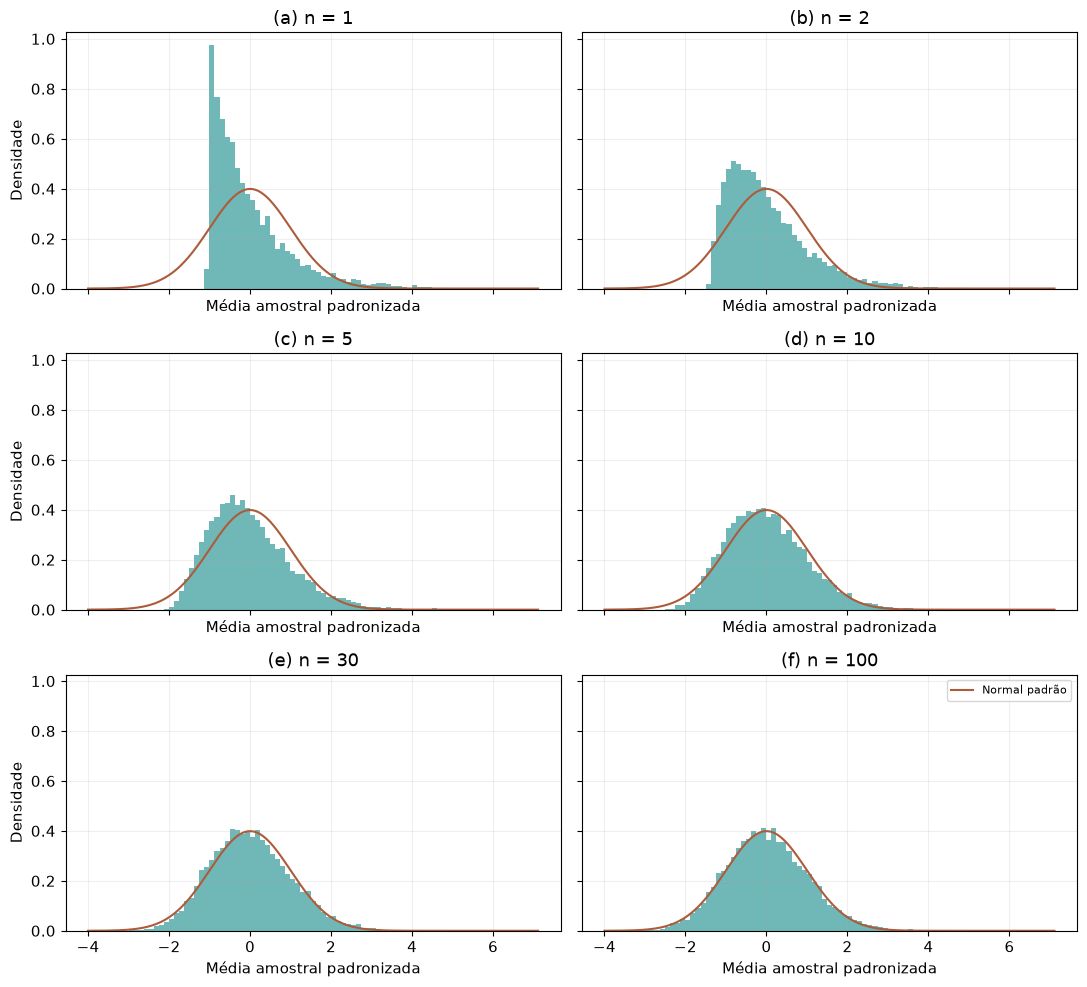

In [23]:
# Compara as médias padronizadas com a Normal padrão sem excluir as caudas simuladas.
fig, axes = plt.subplots(3, 2, figsize=(11, 10), sharex=True, sharey=True)
axes = axes.ravel()
z_sim = {n: (med_fig[n] - mu) / ep_med(sigma, n, N, rep=True) for n in tam_fig}
z_min = min(-4, min(val.min() for val in z_sim.values()))
z_max = max(4, max(val.max() for val in z_sim.values()))
grade = np.linspace(z_min, z_max, 1000)
for ax, n, letra in zip(axes, tam_fig, 'abcdef'):
    ax.hist(z_sim[n], bins=np.linspace(z_min, z_max, 90), density=True, color='#339999', alpha=.7)
    ax.plot(grade, stats.norm.pdf(grade), color='#ad5c3b', label='Normal padrão')
    ax.set(title=f'({letra}) n = {n}', xlabel='Média amostral padronizada')
for ax in axes[::2]:
    ax.set_ylabel('Densidade')
axes[-1].legend(fontsize=8)
fig.tight_layout()
plt.show()

**Figura 9 - Distribuições das médias amostrais padronizadas e referência Normal padrão.** Em (a), $n=1$ mantém a forte assimetria das rendas individuais. Em (b), $n=2$ ainda apresenta assimetria e difere da curva Normal. Em (c), $n=5$ reduz a assimetria, mas mantém diferenças em relação à referência. Em (d), $n=10$ apresenta maior proximidade com a Normal padrão. Em (e), $n=30$ aproxima a forma do histograma da referência. Em (f), $n=100$ apresenta maior concordância com a curva Normal. Os painéis padronizam as mesmas 10.000 médias amostrais de cada tamanho usadas na Figura 8. A padronização permite comparar as formas sem o efeito da redução de escala. Fonte: CARUBBI, 2026.

#### 7.3.3. Interpretação

O centro teórico permanece em aproximadamente 3,000 SM. A variância da média cai de 8,730 SM², com $n=1$, para 0,02183 SM², com $n=400$.

Na escala padronizada, a divisão pelo erro-padrão mantém a variância teórica em 1. Nessa escala, comparamos principalmente a forma com a Normal padrão. O TCL não torna a população de rendas Normal.

**Tamanho amostral $n$** determina quantas observações entram em cada média. **Número de repetições $B$** determina quantas médias usamos para descrever sua distribuição por Monte Carlo. Aumentar $B$ melhora a descrição empírica para $n$ fixo. A redução do erro-padrão decorre do aumento de $n$ sob o mecanismo especificado.

## 8. Estimador, estimativa, viés e precisão

### 8.1. Contexto

Na pesquisa sobre renda, a média de uma amostra é usada para estimar o rendimento domiciliar per capita médio da população. Outra amostra poderia fornecer uma estimativa diferente.

Em sucessivas repetições, essas estimativas se concentram em torno da média populacional? Quanto elas variam entre si?

Essa análise permite avaliar o *viés*, relacionado à tendência de superestimar ou subestimar a média populacional, e a *precisão*, maior quando as estimativas variam menos entre amostras.

### 8.2. Fundamentação teórica

Um **estimador** é uma *regra aplicada a uma amostra aleatória*. Sua **estimativa** é o *resultado observado depois da coleta*. Para um parâmetro genérico, o estimador e seu viés são representados por

$$
\widehat\theta=T(X_1,\ldots,X_n),\qquad
\operatorname{Viés}(\widehat\theta)=\mathbb E[\widehat\theta]-\theta.
\tag{2.1}
$$

$\theta$ é o parâmetro populacional, $\widehat\theta$ é o estimador aleatório e $T$ é a regra de cálculo. A estimativa observada é $\hat\theta=T(x_1,\ldots,x_n)$. O viés tem a unidade do parâmetro.

Por exemplo, para estimar a renda média de uma população, podemos usar a regra de somar as rendas de uma amostra e dividir pelo número de pessoas observadas. Essa regra define a média amostral como *estimador* da média populacional. O valor obtido em uma amostra específica é uma *estimativa*. Outra amostra pode produzir uma estimativa diferente, mesmo usando o mesmo estimador.

Um estimador **não viesado** tem *esperança igual ao parâmetro*. A **precisão** depende de sua *dispersão em repetições*. Uma regra pode ter centro correto e dispersão elevada. A qualidade da seleção amostral também afeta o alcance das conclusões, conforme Barbetta, Reis e Bornia (2010).

<div style="max-width: 760px; margin: 0 auto; text-align: center">
<img src="https://raw.githubusercontent.com/carubbi/MQ/main/notebooks/assets/imgs/u3_s01/barbetta_figura_7_7.png" alt="Figura 10 - Viés e precisão na analogia dos tiros ao alvo. Da esquerda para a direita, T1 é não viesado e mais preciso, T2 é não viesado e menos preciso, e T3 é viesado apesar da concentração de suas estimativas. Fonte: BARBETTA; REIS; BORNIA, 2010." style="display: block; width: 100%; height: auto">
<div style="display: flex"><span style="width: 33.33%">(a)</span><span style="width: 33.33%">(b)</span><span style="width: 33.33%">(c)</span></div>
</div>

**Figura 10 - Viés e precisão na analogia dos tiros ao alvo.** O centro do alvo representa o parâmetro populacional, e cada ponto representa uma estimativa obtida em uma amostra. Em (a), $T_1$ produz estimativas pouco dispersas em torno do parâmetro, ilustrando ausência de viés e maior precisão. Em (b), $T_2$ também é não viesado, mas apresenta maior dispersão e menor precisão que $T_1$. Em (c), $T_3$ produz estimativas concentradas, porém deslocadas do parâmetro, ilustrando que maior precisão não elimina o viés. Fonte: BARBETTA; REIS; BORNIA, 2010.


### 8.3. Aplicação

Retome as 10.000 estimativas da média populacional obtidas para cada tamanho amostral, $n\in\{1,2,5,10,30,100\}$, com reposição. O gráfico a seguir permite comparar o centro e a dispersão dessas estimativas.

Compare a média das estimativas de cada grupo com a média populacional, indicada pela linha tracejada. Em seguida, observe quanto as estimativas variam entre amostras. O aumento de $n$ altera principalmente o centro ou a dispersão? Qual grupo apresenta maior precisão?

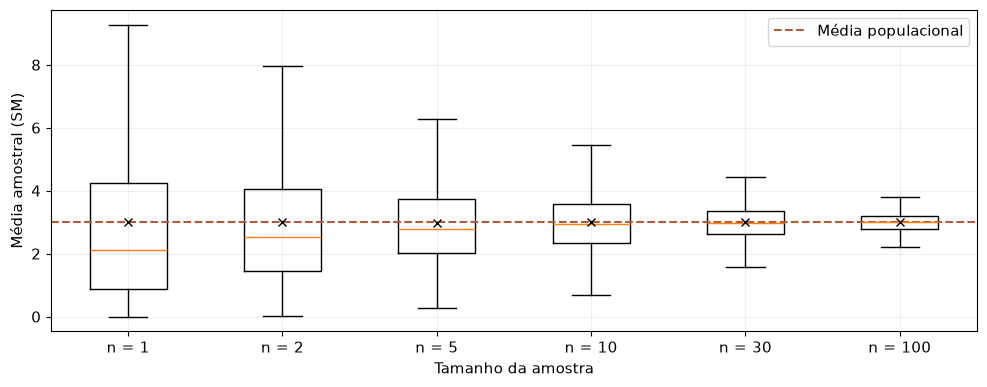

In [24]:
# Compara as estimativas dos seis tamanhos amostrais usados na Figura 8.
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot([med_fig[n] for n in tam_fig], tick_labels=[f'n = {n}' for n in tam_fig], showmeans=True, showfliers=False, meanprops={'marker': 'x', 'markeredgecolor': 'black'})
ax.axhline(mu, color='#ad5c3b', linestyle='--', label='Média populacional')
ax.set(xlabel='Tamanho da amostra', ylabel='Média amostral (SM)')
ax.legend()
fig.tight_layout()
plt.show()

**Figura 11 - Dispersão das estimativas da média em amostras repetidas.** Os marcadores “x” pretos indicam as médias das 10.000 estimativas de cada grupo. As médias das estimativas permanecem próximas de 3,000 SM nos seis tamanhos amostrais. A dispersão diminui conforme $n$ aumenta, indicando maior precisão. Valores além dos limites dos boxplots não são exibidos como pontos. Fonte: CARUBBI, 2026.

#### 8.3.1. Interpretação

Nas condições do experimento, $\bar X$ é um estimador não viesado de $\mu$ para todos os tamanhos amostrais. A média das estimativas permanece próxima de 3,000 SM. A precisão aumenta com o tamanho amostral, pois a dispersão das médias amostrais diminui.

Uma estimativa particular pode ficar acima ou abaixo do parâmetro. Informar o erro-padrão ou um intervalo de confiança ajuda a comunicar a incerteza associada ao processo de estimação. Maior precisão, por si só, também não corrige uma seleção enviesada.

## 9. Intervalo de confiança para proporção

### 9.1. Contexto

Na amostra simulada de 400 observações, 315 correspondem a pessoas com rendimento domiciliar per capita abaixo de 5 SM. A proporção amostral observada é de 78,75%.

Qual intervalo de valores expressa a incerteza associada à estimativa da proporção populacional? Como o nível de confiança escolhido afeta a largura desse intervalo?

### 9.2. Fundamentação teórica

Nas seções anteriores, a média amostral observada $\bar x$ e a proporção amostral observada $\hat p$ foram usadas para estimar $\mu$ e $p$. Cada resultado é uma *estimativa pontual*, pois fornece um único valor. Na pesquisa sobre renda, 78,75% é a estimativa pontual da proporção populacional de pessoas com renda abaixo de 5 SM.

Como amostras diferentes produzem estimativas diferentes, usamos uma *estimativa intervalar* para comunicar essa incerteza por meio de limites inferior e superior. Nesta aplicação, a faixa de 74,74% a 82,76%, que será calculada adiante, é uma estimativa intervalar da mesma proporção populacional.

Um *intervalo de confiança* é uma forma de estimativa intervalar cujo procedimento é construído para que uma proporção especificada dos intervalos obtidos em amostras repetidas contenha o parâmetro populacional. Essa proporção corresponde ao *nível de confiança*.

O nível de confiança de 95% é amplamente utilizado na prática. Outros valores, como 90% e 99%, podem ser escolhidos conforme os objetivos e as exigências do estudo. Essa escolha deve ocorrer antes de observar os resultados da amostra. Para a mesma amostra e o mesmo método, exigir maior confiança produz um intervalo mais amplo.

Retomemos a distribuição amostral da proporção na *AAS com reposição*, com $0<p<1$. Sua esperança é a proporção populacional, e seu erro-padrão é a raiz da variância (BARBETTA; REIS; BORNIA, 2010):

$$
\mathbb E[\widehat P]=p,\qquad
\operatorname{Var}(\widehat P)=\frac{p(1-p)}{n},\qquad
\operatorname{EP}(\widehat P)=\sqrt{\frac{p(1-p)}{n}}.
\tag{2.2}
$$

$p$ é a proporção populacional, $n$ é o tamanho amostral e $\widehat P$ é a proporção amostral aleatória. O erro-padrão expressa sua variabilidade entre amostras. Quando a aproximação Normal é adequada, podemos relacionar essa variabilidade à área central da Normal padrão $Z\sim\mathcal N(0,1)$:

$$
\mathbb P(-1{,}96\leq Z\leq1{,}96)\approx0{,}95.
\tag{2.3}
$$

A Normal padrão tem média 0 e desvio-padrão 1. Assim, os limites −1,96 e 1,96 ficam a aproximadamente dois desvios-padrão da média e delimitam cerca de 95% da distribuição. Ao padronizar a proporção amostral, subtraímos $p$ e dividimos pelo erro-padrão. Reorganizando a desigualdade, obtemos uma expressão com $p$ entre dois limites:

$$
\begin{aligned}
\mathbb P\left(-1{,}96\leq
\frac{\widehat P-p}{\operatorname{EP}(\widehat P)}
\leq1{,}96\right)&\approx0{,}95,\\[6pt]
\mathbb P\left(\widehat P-1{,}96\operatorname{EP}(\widehat P)
\leq p\leq
\widehat P+1{,}96\operatorname{EP}(\widehat P)\right)&\approx0{,}95.
\end{aligned}
\tag{2.4}
$$

As duas expressões descrevem o mesmo evento. O parâmetro $p$ permanece fixo, enquanto a proporção amostral $\widehat P$ e os limites variam entre amostras. Podemos expressar essa relação pelo *erro amostral absoluto* $|\widehat P-p|$:

$$
\mathbb P\left(|\widehat P-p|\leq
1{,}96\operatorname{EP}(\widehat P)\right)\approx0{,}95.
\tag{2.5}
$$

Assim, em amostras repetidas, o afastamento da proporção amostral em relação à proporção populacional fica dentro de aproximadamente 1,96 erros-padrão em 95% das repetições.

Observada a amostra, usamos a proporção amostral observada $\hat p$ no centro dos limites. A construção seria $\hat p\pm1{,}96\operatorname{EP}(\widehat P)$, mas o erro-padrão ainda depende de $p$, desconhecido. Para obter limites calculáveis, substituímos $p$ por sua estimativa $\hat p$:

$$
\hat p=\frac{x}{n},\qquad
\widehat{\operatorname{EP}}(\widehat P)
=\sqrt{\frac{\hat p(1-\hat p)}{n}}.
\tag{2.6}
$$

$x$ é o número de observações com o atributo de interesse, e $\widehat{\operatorname{EP}}(\widehat P)$ é o erro-padrão estimado. Essa substituição conduz ao **intervalo aproximado de Wald** de 95%:

$$
IC_{0{,}95}=\left[
\hat p-1{,}96\sqrt{\frac{\hat p(1-\hat p)}{n}},\quad
\hat p+1{,}96\sqrt{\frac{\hat p(1-\hat p)}{n}}
\right].
\tag{2.7}
$$

Esse intervalo simétrico segue a estrutura *estimativa pontual ± margem de erro*, com centro na proporção amostral observada $\hat p$. A *margem de erro* é $1{,}96\widehat{\operatorname{EP}}(\widehat P)$, subtraída para obter o limite inferior e somada para obter o superior. Em pontos percentuais, multiplicamos essa margem por 100.

<div style="text-align: center">
<img src="https://raw.githubusercontent.com/carubbi/MQ/main/notebooks/assets/imgs/u3_s01/barbetta_esquema_ic_proporcao.png" alt="Figura 12 - Centro e limites do intervalo de confiança para a proporção. A proporção amostral observada ocupa o centro, e a margem de erro determina os dois limites. Fonte: BARBETTA; REIS; BORNIA, 2010." style="width: 760px; max-width: 100%; height: auto">
</div>

**Figura 12 - Centro e limites do intervalo de confiança para a proporção.** O ponto central representa a estimativa pontual $\hat p$. Os pontos laterais delimitam a estimativa intervalar, obtida subtraindo e somando a margem de erro. Na notação da figura, $s_{\hat p}$ representa o erro-padrão estimado, denotado no notebook por $\widehat{\operatorname{EP}}(\widehat P)$. Fonte: BARBETTA; REIS; BORNIA, 2010.

Um nível de confiança de 95% significa que, se repetíssemos a seleção da amostra e a construção do intervalo pelo mesmo procedimento, aproximadamente 95% dos intervalos conteriam a proporção populacional, desde que a aproximação utilizada fosse adequada. Para cada amostra observada, o intervalo tem limites determinados. O parâmetro populacional é fixo.

Podemos escolher outros níveis de confiança. Para um *nível de confiança* $1-\alpha$, com $0<\alpha<1$, o *valor crítico* $z_{1-\alpha/2}$ é o quantil da Normal padrão que determina o limite positivo da área central. Como construímos um intervalo bilateral central, distribuímos a probabilidade restante $\alpha$ igualmente entre as duas caudas, com $\alpha/2$ em cada uma.

<div style="text-align: center">
<img src="https://raw.githubusercontent.com/carubbi/MQ/main/notebooks/assets/imgs/u3_s01/barbetta_figura_7_8.png" alt="Figura 13 - Área central da Normal padrão e valores críticos. A área central corresponde ao nível de confiança, e cada cauda contém metade da probabilidade restante. A tabela relaciona níveis de confiança aos valores críticos. Fonte: BARBETTA; REIS; BORNIA, 2010." style="width: 720px; max-width: 100%; height: auto">
</div>

**Figura 13 - Área central da Normal padrão e valores críticos.** A área sombreada corresponde ao nível de confiança $\gamma=1-\alpha$. Na notação da figura, $z_\gamma$ corresponde a $z_{1-\alpha/2}$ no notebook. Para 95% de confiança, a área central é 0,95. Restam 0,05 nas duas caudas, ou 0,025 em cada uma. O limite positivo é o quantil de probabilidade acumulada 0,975, aproximadamente 1,96, correspondente a quase dois desvios-padrão acima da média da Normal padrão. Para 99%, o valor crítico é aproximadamente 2,576. Maior confiança exige uma área central maior e amplia a margem de erro para a mesma amostra. Fonte: BARBETTA; REIS; BORNIA, 2010.

Substituindo 1,96 pelo quantil escolhido, generalizamos o intervalo de Wald para o nível de confiança $1-\alpha$:

$$
IC_{1-\alpha}=\left[
\hat p-z_{1-\alpha/2}\widehat{\operatorname{EP}}(\widehat P),\quad
\hat p+z_{1-\alpha/2}\widehat{\operatorname{EP}}(\widehat P)
\right].
\tag{2.8}
$$

Para a mesma amostra e o mesmo método, *maior confiança produz maior largura*. A aproximação exige observações independentes de Bernoulli e contagens suficientes de sucessos e fracassos. O tamanho total da amostra, isoladamente, não garante boa cobertura. O método de Wald pode ter cobertura inadequada em amostras pequenas ou proporções próximas de zero ou um (BARBETTA; REIS; BORNIA, 2010; MONTGOMERY; RUNGER, 2018).


### 9.3. Aplicação

Calcule estimativa, erro-padrão, margem de erro e limites a 95%. Em seguida, explique a diferença de largura em relação ao intervalo de 99% fornecido.

#### 9.3.1. Implementação sem pacotes

A função abaixo aplica a estrutura estimativa mais ou menos margem. O quantil será obtido pelo pacote.

In [25]:
# Define os limites de um intervalo simétrico em torno da estimativa.
def lim_ic(est, q, ep):
    """Calcula os limites usando a margem quantil vezes erro-padrão."""
    margem = q * ep
    return est - margem, est + margem

In [26]:
# Seleciona uma única amostra para os intervalos e os testes da Aula 2.
n_inf = 400
rng_inf = np.random.default_rng(47)
am_inf = rng_inf.choice(renda, size=n_inf, replace=True)
x_inf = int((am_inf < 5).sum())
phat = x_inf / n_inf

# Calcula o IC de 95% pela expressão direta.
alfa_ic = 0.05
ep_phat = ep_prop(phat, n_inf, N, rep=True)
z_95 = stats.norm.ppf(1 - alfa_ic / 2)
ic_p95 = lim_ic(phat, z_95, ep_phat)
print(f'Pessoas com renda < 5 SM: {x_inf} em {n_inf}')
print(f'Estimativa = {phat:.4f}, demais pessoas = {n_inf - x_inf}')
print(f'Erro-padrão estimado = {ep_phat:.6f}')
print(f'Margem de erro = {z_95 * ep_phat:.6f}')
print(f'IC de 95% = [{ic_p95[0]:.6f}, {ic_p95[1]:.6f}]')

Pessoas com renda < 5 SM: 315 em 400
Estimativa = 0.7875, demais pessoas = 85
Erro-padrão estimado = 0.020454
Margem de erro = 0.040089
IC de 95% = [0.747411, 0.827589]


#### 9.3.2. Implementação com pacotes

Informamos <code>method='normal'</code> para conferir o mesmo intervalo de Wald. O intervalo de 99% será apresentado pronto para interpretação. [Documentação de proportion_confint](https://www.statsmodels.org/v0.14.6/generated/statsmodels.stats.proportion.proportion_confint.html) (STATSMODELS DEVELOPERS, 2025).

In [27]:
# Confere o IC de 95% e fornece o de 99% pelo mesmo método.
ic_p95_pac = proportion_confint(x_inf, n_inf, alpha=0.05, method='normal')
ic_p99 = proportion_confint(x_inf, n_inf, alpha=0.01, method='normal')
display(pd.DataFrame({
    'Proc.': ['Expr. 95%', 'Pac. 95%', 'Pac. 99%'],
    'LI': [ic_p95[0], ic_p95_pac[0], ic_p99[0]],
    'LS': [ic_p95[1], ic_p95_pac[1], ic_p99[1]],
}))

,Proc.,LI,LS
0,Expr. 95%,0.747411,0.827589
1,Pac. 95%,0.747411,0.827589
2,Pac. 99%,0.734814,0.840186


**Tabela 11 - Intervalos de Wald para a proporção com renda abaixo de 5 SM.** O IC de 95% vai de 74,74% a 82,76%. O IC de 99% vai de 73,48% a 84,02% e é mais largo para a mesma amostra. **Legenda.** Proc. = procedimento. Expr. = cálculo pela expressão. Pac. = cálculo pelo pacote statsmodels. LI e LS = limites inferior e superior da proporção. IC = intervalo de confiança. Os percentuais em Proc. indicam o nível de confiança. SM = salário mínimo de referência. Fonte: CARUBBI, 2026.

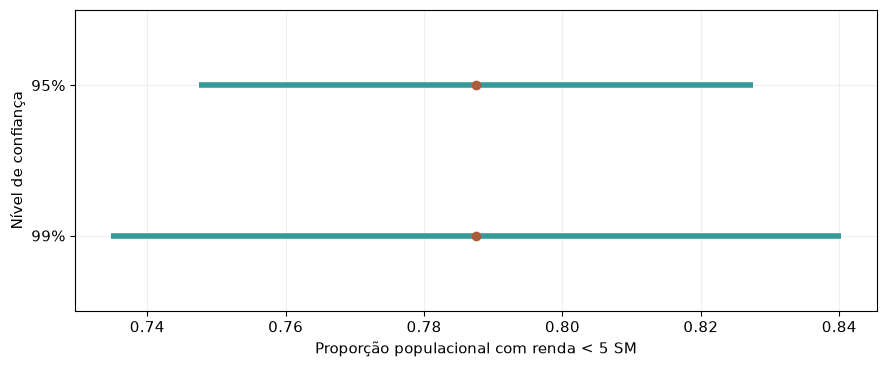

In [28]:
# Desenha os dois intervalos na mesma escala de proporções.
fig, ax = plt.subplots()
for y, ic in [(1, ic_p95), (0, ic_p99)]:
    ax.hlines(y, ic[0], ic[1], color='#339999', linewidth=4)
    ax.plot(phat, y, 'o', color='#ad5c3b')
ax.set(yticks=[0, 1], yticklabels=['99%', '95%'], xlabel='Proporção populacional com renda < 5 SM', ylabel='Nível de confiança', ylim=(-0.5, 1.5))
fig.tight_layout()
plt.show()

**Figura 14 - Intervalos de confiança de 95% e 99% para a proporção.** A estimativa pontual é a mesma. A elevação da confiança aumenta a margem de erro e a largura do intervalo. Fonte: CARUBBI, 2026.

#### 9.3.3. Interpretação

A amostra contém 315 pessoas com renda abaixo de 5 SM, correspondendo a 78,75%. As contagens de pessoas com e sem o atributo são suficientemente grandes para esta aplicação aproximada de Wald. O IC de 95% vai de **74,74% a 82,76%**.

O IC de 99% tem maior largura. A confiança descreve a cobertura do procedimento em amostras repetidas, sob suas condições. Ela não é a probabilidade de o parâmetro fixo pertencer a este intervalo já calculado.

Como conferência didática, a proporção da população completa é 81,29% e pertence aos dois intervalos observados. Essa ocorrência isolada não estima a cobertura do método.

## 10. Intervalo de confiança para média

### 10.1. Contexto

Na mesma amostra de 400 observações, o rendimento domiciliar per capita apresentou média amostral de 3,135 SM e desvio-padrão amostral de 2,971 SM.

Como construir um intervalo de 95% de confiança para a média populacional quando o desvio-padrão da população é desconhecido?

O intervalo permite comunicar a incerteza associada à renda média estimada para a população.

In [29]:
# Resume a amostra comum às aplicações inferenciais.
display(pd.DataFrame({
    'n': [n_inf],
    'Mín (SM)': [am_inf.min()],
    'Máx (SM)': [am_inf.max()],
    'M (SM)': [am_inf.mean()],
    'DP (SM)': [am_inf.std(ddof=1)],
}))

,n,Mín (SM),Máx (SM),M (SM),DP (SM)
0,400,0.004660,18.894488,3.134665,2.970826


**Tabela 12 - Resumo das rendas na amostra de 400 pessoas.** Os valores mínimo e máximo descrevem a amplitude das rendas individuais. O intervalo a ser calculado estima a média populacional, sem pretender conter uma proporção especificada de rendas individuais. **Legenda.** n = número de pessoas na amostra. Mín e Máx = rendas mínima e máxima. M = renda média. DP = desvio-padrão amostral das rendas. SM = salário mínimo de referência. Fonte: CARUBBI, 2026.

### 10.2. Fundamentação teórica

Quando $\sigma$ é desconhecido, o *desvio-padrão amostral* fornece uma estimativa. Em uma amostra iid de população Normal, a **estatística padronizada para a média** tem *distribuição t de Student* com $n-1$ *graus de liberdade*. O intervalo correspondente é

$$
T=\frac{\bar X-\mu}{S/\sqrt n}\sim t_{n-1},\qquad
IC_{1-\alpha}=\left[\bar x-t_{1-\alpha/2,n-1}\frac{s}{\sqrt n},\ \bar x+t_{1-\alpha/2,n-1}\frac{s}{\sqrt n}\right].
\tag{2.9}
$$

$\bar X$ é a média amostral aleatória e $\bar x$ é a média amostral observada. Neste bloco, $S$ representa o desvio-padrão amostral aleatório, e $s$ é seu valor calculado na amostra. $\mu$ é a média populacional e $t_{1-\alpha/2,n-1}$ é o quantil t com $n-1$ graus de liberdade. O *erro-padrão estimado* é $s/\sqrt n$, com a unidade da variável. Ao calcular os desvios em torno da média estimada, a soma dos desvios é zero, restando $n-1$ desvios livres.

Conhecer $s$ após observar a amostra continua sendo diferente de conhecer $\sigma$ populacional. A t considera a incerteza de estimar $\sigma$. A Normal é a referência para a média amostral padronizada com $\sigma$ conhecido sob as condições apropriadas. A exatidão do procedimento t pressupõe *observações iid de população Normal*, e amostras pequenas exigem especial atenção a esse modelo, conforme Barbetta, Reis e Bornia (2010).

Em populações não Normais com variância finita, o procedimento pode ser usado *aproximadamente em amostras suficientemente grandes*, apoiado na aproximação Normal da distribuição amostral da média e na estimação de seu erro-padrão. Não existe um tamanho universal que assegure boa aproximação. Nesta população assimétrica, adotaremos $n=400$ e um intervalo bilateral de 95%, sem afirmar exatidão da referência t.

<div style="text-align: center">
<img src="https://raw.githubusercontent.com/carubbi/MQ/main/notebooks/assets/imgs/u3_s01/barbetta_figura_7_9.png" alt="Figura 15 - Distribuição t de Student e Normal padrão. As caudas da t são mais largas, com maior diferença para poucos graus de liberdade. O aumento dos graus de liberdade aproxima a t da Normal padrão. Fonte: Barbetta, Reis e Bornia (2010)." style="width: 720px; max-width: 100%; height: auto">
</div>

**Figura 15 - Distribuição t de Student e Normal padrão.** As caudas da t são mais largas, com maior diferença para poucos graus de liberdade. O aumento dos graus de liberdade aproxima a t da Normal padrão. Fonte: Barbetta, Reis e Bornia (2010).

### 10.3. Aplicação

Calcule a média amostral, o desvio-padrão amostral e o erro-padrão estimado da média amostral usando a amostra já selecionada. Preserve os resultados para o teste da seção 13. Obtenha o quantil t pelo pacote e aplique a função de intervalo.

#### 10.3.1. Implementação sem pacotes

As medidas descritivas são obtidas por NumPy, como nas aulas anteriores. A construção dos limites reutiliza a função desenvolvida na seção 9.

In [30]:
# Resume a amostra uma única vez para o intervalo e o teste da média.
media_t = am_inf.mean()
s_t = am_inf.std(ddof=1)
ep_t = ep_med(s_t, n_inf, N, rep=True)
gl_t = n_inf - 1

# Obtém o quantil t e aplica a função de intervalo.
t_95 = stats.t.ppf(0.975, df=gl_t)
ic_t95 = lim_ic(media_t, t_95, ep_t)
print(f'n = {n_inf}, graus de liberdade = {gl_t}')
print(f'Média = {media_t:.6f} SM, desvio-padrão = {s_t:.6f} SM')
print(f'Erro-padrão = {ep_t:.6f} SM, quantil t = {t_95:.6f}')
print(f'IC de 95% = [{ic_t95[0]:.6f}, {ic_t95[1]:.6f}] SM')

n = 400, graus de liberdade = 399
Média = 3.134665 SM, desvio-padrão = 2.970826 SM
Erro-padrão = 0.148541 SM, quantil t = 1.965927
IC de 95% = [2.842644, 3.426687] SM


#### 10.3.2. Implementação com pacotes

<code>stats.sem</code> calcula o erro-padrão estimado da média e usa <code>ddof=1</code> por padrão. Em <code>stats.t.interval</code>, <code>df</code> recebe os graus de liberdade, <code>loc</code> recebe a média e <code>scale</code> recebe o erro-padrão. [Documentação de sem](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.sem.html) e [da distribuição t](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.t.html) (SCIPY COMMUNITY, 2026).

In [31]:
# Confere os resumos e os limites com SciPy e NumPy.
ep_t_pac = stats.sem(am_inf, ddof=1)
ic_t_pac = stats.t.interval(confidence=0.95, df=gl_t, loc=media_t, scale=ep_t_pac)
display(pd.DataFrame({
    'Med.': ['M', 'DP', 'EP', 'LI', 'LS'],
    'Expr.': [media_t, s_t, ep_t, *ic_t95],
    'Pac.': [np.mean(am_inf), np.std(am_inf, ddof=1), ep_t_pac, *ic_t_pac],
}))

,Med.,Expr.,Pac.
0,M,3.134665,3.134665
1,DP,2.970826,2.970826
2,EP,0.148541,0.148541
3,LI,2.842644,2.842644
4,LS,3.426687,3.426687


**Tabela 13 - Conferência do intervalo para a renda média.** As implementações coincidem. A média é 3,135 SM e o erro-padrão estimado é 0,149 SM. O IC aproximado de 95% vai de 2,843 a 3,427 SM. **Legenda.** Med. = medida. M = renda média. DP = desvio-padrão amostral. EP = erro-padrão estimado da média. LI e LS = limites inferior e superior do intervalo. Expr. = cálculo pela expressão. Pac. = cálculo com NumPy e SciPy. Todas as medidas estão em salários mínimos de referência (SM). IC = intervalo de confiança. Fonte: CARUBBI, 2026.

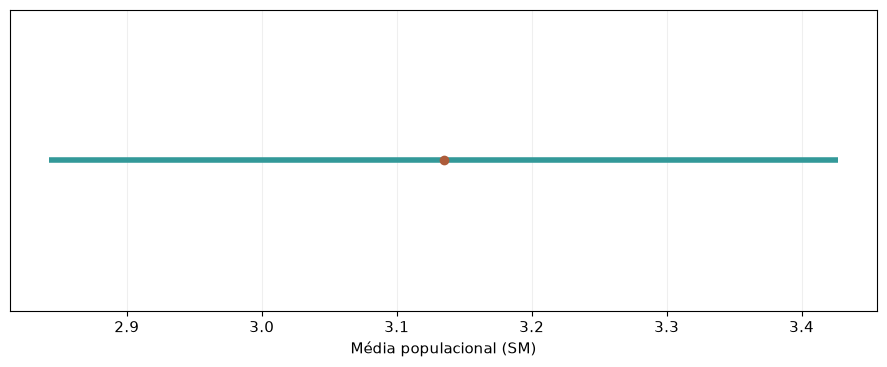

In [32]:
# Apresenta o intervalo para a renda média.
fig, ax = plt.subplots()
ax.hlines(0, ic_t95[0], ic_t95[1], color='#339999', linewidth=4)
ax.plot(media_t, 0, 'o', color='#ad5c3b')
ax.set(xlabel='Média populacional (SM)', yticks=[], ylim=(-0.5, 0.5))
fig.tight_layout()
plt.show()

**Figura 16 - Intervalo aproximado de 95% para a renda média.** A estimativa de 3,135 SM é acompanhada do intervalo de 2,843 a 3,427 SM. A largura expressa incerteza da média, não dispersão das rendas individuais. Fonte: CARUBBI, 2026.

#### 10.3.3. Interpretação

Obtivemos média de 3,135 SM e erro-padrão estimado de 0,149 SM. Com 399 graus de liberdade, o IC aproximado de 95% é **[2,843, 3,427] SM**.

O desvio-padrão amostral descreve a dispersão das rendas individuais. O erro-padrão estimado descreve a incerteza da média. A referência t é exata para amostras iid Normais. Nesta aplicação, sua validade é aproximada, pois a população é assimétrica.

A média da população completa, aproximadamente 3,000 SM, pertence ao intervalo observado. A disponibilidade desse valor é um recurso de conferência da simulação e não entra no cálculo dos limites.

## 11. Raciocínio dos testes de hipóteses

### 11.1. Contexto

A pesquisa avalia a afirmação de que 80% das pessoas da população têm rendimento domiciliar per capita abaixo de 5 SM. Em dois cenários hipotéticos, cada um com dez observações amostrais, quatro ou sete registros apresentam essa condição.

Esses resultados fornecem a mesma evidência contra a afirmação? Como avaliar se cada resultado é suficiente para questioná-la?

### 11.2. Fundamentação teórica

Um teste confronta os dados com uma **hipótese nula**, $H_0$, usando uma *distribuição de referência*. A **hipótese alternativa**, $H_1$, define a *direção da investigação*. Em um teste bilateral, a alternativa considera desvios nos dois sentidos em relação ao valor especificado sob $H_0$.

O **valor-p** é a probabilidade, sob $H_0$ e as *demais condições do modelo*, de obter uma estatística *tão ou mais extrema que a observada*, na direção de $H_1$. Para uma estatística contínua $W$, com função de distribuição $F_0$ simétrica em torno de zero sob $H_0$, temos

$$
\text{valor-p}=
\begin{cases}
F_0(w_{\mathrm{obs}}),&\text{alternativa à esquerda},\\
1-F_0(w_{\mathrm{obs}}),&\text{alternativa à direita},\\
2\bigl[1-F_0(|w_{\mathrm{obs}}|)\bigr],&\text{alternativa bilateral}.
\end{cases}
\tag{2.10}
$$

$w_{\mathrm{obs}}$ é a estatística observada e $F_0$ depende da referência escolhida, como Normal padrão ou t de Student. Em testes discretos, o critério bilateral precisa ser especificado. No teste Binomial exato usado aqui, somamos as probabilidades dos resultados cuja probabilidade sob $H_0$ é menor ou igual à do resultado observado. Não aplicamos automaticamente a fórmula contínua simétrica à contagem Binomial.

O **nível de significância** $\alpha$ é *fixado antes de observar o resultado*. Rejeitamos $H_0$ quando o valor-p é menor ou igual a $\alpha$. Caso contrário, **não rejeitamos $H_0$**. Essa regra controla a probabilidade de erro I sob as condições do procedimento. Em testes discretos, ela pode ser inferior a $\alpha$.

| Dec. | $H_0$ V | $H_0$ F |
|---|---|---|
| R $H_0$ | *Erro I* | Detecção de uma diferença |
| NR $H_0$ | Decisão correta | *Erro II* |

**Tabela 14 - Decisões e erros em testes de hipóteses.** Rejeitar uma hipótese nula verdadeira caracteriza o erro I. Deixar de rejeitar uma hipótese nula falsa caracteriza o erro II. **Legenda.** Dec. = decisão. H₀ = hipótese nula. V = verdadeira. F = falsa. R = rejeitar. NR = não rejeitar. Fonte: elaboração didática com base em Barbetta, Reis e Bornia (2010).

O valor-p não é a probabilidade de $H_0$ ser verdadeira nem a probabilidade de a decisão observada estar errada. Uma não rejeição não comprova $H_0$. A significância estatística também não mede a magnitude ou a importância de uma diferença (AMERICAN STATISTICAL ASSOCIATION, 2016).

### 11.3. Aplicação

Para tornar visível o raciocínio, considere dois **cenários hipotéticos**, cada um com dez seleções independentes com reposição: quatro pessoas ou sete pessoas com renda abaixo de 5 SM. Esses resultados foram especificados para comparação didática e não correspondem à amostra de 400 pessoas.

Adotamos $H_0:p=0{,}80$, $H_1:p\ne0{,}80$ e $\alpha=0{,}05$. Sob $H_0$, a contagem $K$ segue uma Binomial com $n=10$ e $p_0=0{,}80$. A referência prevê, em média, oito pessoas com o atributo.

A conferência exata e os gráficos são fornecidos prontos. O destaque considera os resultados com probabilidade sob $H_0$ menor ou igual à probabilidade do resultado observado, conforme o critério bilateral de `stats.binomtest`. Como $p_0\ne0{,}5$, os destaques não precisam ser simétricos em torno de $np_0$ (SCIPY COMMUNITY, 2026).

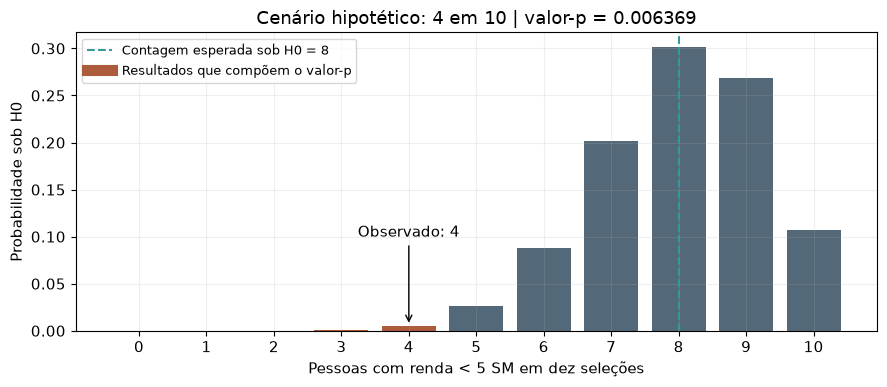

In [33]:
# Destaca os resultados que compõem o valor-p bilateral exato.
k_obs = 4
n_cen = 10
p0_cen = 0.80
k_ref = np.arange(n_cen + 1)
prob_ref = stats.binom.pmf(k_ref, n_cen, p0_cen)
prob_obs = stats.binom.pmf(k_obs, n_cen, p0_cen)
cauda = prob_ref <= prob_obs * (1 + 1e-12)
p_exato = stats.binomtest(k_obs, n_cen, p0_cen, alternative='two-sided').pvalue
assert np.isclose(prob_ref[cauda].sum(), p_exato)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(k_ref, prob_ref, color=np.where(cauda, '#ad5c3b', '#536878'))
ax.axvline(n_cen * p0_cen, color='#339999', linestyle='--', label='Contagem esperada sob H0 = 8')
ax.plot([], [], color='#ad5c3b', linewidth=8, label='Resultados que compõem o valor-p')
ax.annotate('Observado: 4', xy=(k_obs, prob_obs), xytext=(k_obs, max(prob_obs + .06, .10)), ha='center', arrowprops={'arrowstyle': '->'})
ax.set(xticks=k_ref, xlabel='Pessoas com renda < 5 SM em dez seleções', ylabel='Probabilidade sob H0', title=f'Cenário hipotético: {k_obs} em 10 | valor-p = {p_exato:.6f}')
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

**Figura 17 - Teste Binomial exato para 4 pessoas em dez seleções.** Sob a hipótese de 80%, o valor-p bilateral é aproximadamente 0,006369. Os resultados destacados são as contagens de 0 a 4, levando à rejeição de H0 a 5%. O cenário é hipotético. Fonte: CARUBBI, 2026.

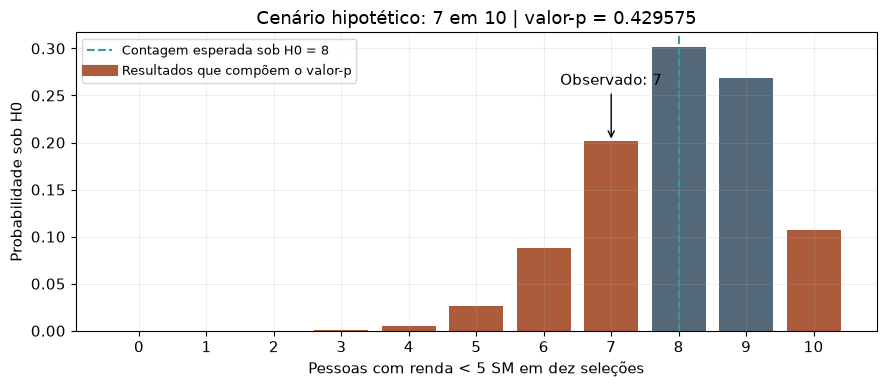

In [34]:
# Destaca os resultados que compõem o valor-p bilateral exato.
k_obs = 7
n_cen = 10
p0_cen = 0.80
k_ref = np.arange(n_cen + 1)
prob_ref = stats.binom.pmf(k_ref, n_cen, p0_cen)
prob_obs = stats.binom.pmf(k_obs, n_cen, p0_cen)
cauda = prob_ref <= prob_obs * (1 + 1e-12)
p_exato = stats.binomtest(k_obs, n_cen, p0_cen, alternative='two-sided').pvalue
assert np.isclose(prob_ref[cauda].sum(), p_exato)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(k_ref, prob_ref, color=np.where(cauda, '#ad5c3b', '#536878'))
ax.axvline(n_cen * p0_cen, color='#339999', linestyle='--', label='Contagem esperada sob H0 = 8')
ax.plot([], [], color='#ad5c3b', linewidth=8, label='Resultados que compõem o valor-p')
ax.annotate('Observado: 7', xy=(k_obs, prob_obs), xytext=(k_obs, max(prob_obs + .06, .10)), ha='center', arrowprops={'arrowstyle': '->'})
ax.set(xticks=k_ref, xlabel='Pessoas com renda < 5 SM em dez seleções', ylabel='Probabilidade sob H0', title=f'Cenário hipotético: {k_obs} em 10 | valor-p = {p_exato:.6f}')
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

**Figura 18 - Teste Binomial exato para 7 pessoas em dez seleções.** Sob a hipótese de 80%, o valor-p bilateral é aproximadamente 0,429575. As contagens destacadas são de 0 a 7 e 10, levando à não rejeição de H0 a 5%. O cenário é hipotético. Fonte: CARUBBI, 2026.

#### 11.3.1. Implementação com pacotes

<code>stats.binomtest</code> recebe a contagem observada, o tamanho amostral, a probabilidade sob a hipótese e a alternativa. Seu resultado confere a soma das probabilidades destacadas nos gráficos. [Documentação de binomtest](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.binomtest.html) (SCIPY COMMUNITY, 2026).

In [35]:
# Confere os dois cenários hipotéticos com o mesmo teste e o mesmo nível.
alfa_cen = 0.05
tab_cen = []
for k in (4, 7):
    teste_cen = stats.binomtest(k=k, n=10, p=.80, alternative='two-sided')
    tab_cen.append({
        'k': k,
        'p-val': teste_cen.pvalue,
        'Dec. (5%)': 'R H0' if teste_cen.pvalue <= alfa_cen else 'NR H0',
    })
display(pd.DataFrame(tab_cen))

,k,p-val,Dec. (5%)
0,4,0.006369,R H0
1,7,0.429575,NR H0


**Tabela 15 - Decisões nos dois cenários hipotéticos.** Quatro pessoas em dez seleções levam à rejeição de p = 0,80, com valor-p aproximado de 0,006369. Sete pessoas levam à não rejeição, com valor-p de 0,429575. **Legenda.** k = número de pessoas com renda abaixo de 5 salários mínimos de referência (SM) em dez seleções. p-val = valor-p bilateral. Dec. (5%) = decisão ao nível de significância de 5%. R H0 = rejeitar a hipótese nula. NR H0 = não rejeitar a hipótese nula. Fonte: CARUBBI, 2026.

#### 11.3.2. Interpretação

O cenário com quatro pessoas apresenta evidência contra a hipótese de 80% ao nível de 5%. O cenário com sete pessoas não fornece evidência suficiente para rejeitá-la nesse nível. A não rejeição não comprova que a proporção seja 80%.

Os valores-p foram calculados sob a hipótese e o mecanismo de seleção. Eles não informam a probabilidade de a hipótese ser verdadeira. Comunique hipóteses, condições, resultado, valor-p, decisão e magnitude da diferença observada.

## 12. Teste para proporção populacional

### 12.1. Contexto

Na amostra de 400 observações, 315 correspondem a pessoas com rendimento domiciliar per capita abaixo de 5 SM, representando 78,75% dos registros. A pesquisa avalia a afirmação de que essa proporção é de 80% na população.

Ao nível de significância de 5%, os dados fornecem evidência suficiente de que a proporção populacional difere de 80%?

### 12.2. Fundamentação teórica

Para observações independentes com o mesmo parâmetro de Bernoulli, o teste de $H_0:p=p_0$ usa

$$
Z=\frac{\widehat P-p_0}{\sqrt{p_0(1-p_0)/n}}
\ \overset{H_0}{\approx}\ \mathcal N(0,1).
\tag{2.11}
$$

$\widehat P$ é a proporção amostral aleatória, $p_0$ é a proporção sob $H_0$ e $n$ é o tamanho da amostra. A estatística observada $z_{\mathrm{obs}}$ substitui $\widehat P$ por $\hat p$. O *erro-padrão do denominador* é calculado **sob $H_0$**. Avaliamos a aproximação a partir das *contagens esperadas* $np_0$ e $n(1-p_0)$.

Empregaremos o *teste de escore* sem correção de continuidade, com *referência Normal padrão*. A formulação é apresentada por Montgomery e Runger (2018). O IC de Wald da seção 9 usa $\hat p$ no erro-padrão. Os dois procedimentos não têm equivalência exata.

### 12.3. Aplicação

Sob a hipótese de 80%, as contagens esperadas são 320 pessoas com o atributo e 80 sem ele, sustentando a referência Normal aproximada. As observações foram selecionadas independentemente e com reposição.

#### 12.3.1. Implementação sem pacotes

A função seguinte padroniza uma estimativa por seu erro-padrão. O valor-p é obtido da Normal padrão pelo pacote.

In [36]:
# Define a padronização de uma estimativa em relação a uma referência.
def est_pad(est, ref, ep):
    """Expressa a diferença em unidades de erro-padrão."""
    return (est - ref) / ep

In [37]:
# Calcula o erro-padrão sob H0 e a estatística observada.
p0 = 0.80
alfa_p = 0.05
ep_h0 = ep_prop(p0, n_inf, N, rep=True)
z_obs = est_pad(phat, p0, ep_h0)
p_z = 2 * stats.norm.sf(abs(z_obs))
print(f'Proporção observada = {phat:.4f}')
print(f'EP sob H0 = {ep_h0:.6f}, z = {z_obs:.6f}')
print(f'Valor-p bilateral = {p_z:.10f}')
print('Decisão:', 'rejeitar H0' if p_z <= alfa_p else 'não rejeitar H0')

Proporção observada = 0.7875
EP sob H0 = 0.020000, z = -0.625000
Valor-p bilateral = 0.5319710581
Decisão: não rejeitar H0


#### 12.3.2. Implementação com pacotes

Em <code>proportions_ztest</code>, <code>value=p0</code> fixa a hipótese e <code>alternative='two-sided'</code> fixa a alternativa. Informar <code>prop_var=p0</code> faz o pacote usar a variância sob a hipótese, conferindo a fórmula desenvolvida. [Documentação de proportions_ztest](https://www.statsmodels.org/v0.14.6/generated/statsmodels.stats.proportion.proportions_ztest.html) (STATSMODELS DEVELOPERS, 2025).

In [38]:
# Confere o teste de escore sem correção de continuidade.
z_pac, p_pac = proportions_ztest(
    count=x_inf, nobs=n_inf, value=p0,
    alternative='two-sided', prop_var=p0,
)
display(pd.DataFrame({
    'Med.': ['z', 'p-val'],
    'Expr.': [z_obs, p_z],
    'Pac.': [z_pac, p_pac],
}))

,Med.,Expr.,Pac.
0,z,-0.625000,-0.625000
1,p-val,0.531971,0.531971


**Tabela 16 - Conferência do teste para a proporção com renda abaixo de 5 SM.** Os procedimentos coincidem em z = -0,625 e valor-p bilateral de 0,531971. A hipótese de 80% não é rejeitada ao nível de 5%. **Legenda.** Med. = medida. z = estatística observada do teste de proporção. p-val = valor-p bilateral. Expr. = cálculo pela expressão. Pac. = cálculo pelo statsmodels. SM = salário mínimo de referência. Fonte: CARUBBI, 2026.

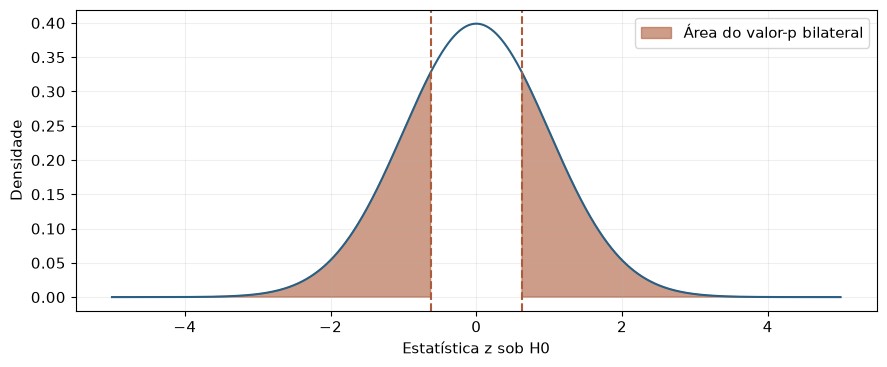

In [39]:
# Destaca as duas caudas do valor-p na referência Normal padrão.
eixo_z = np.linspace(-5, 5, 3001)
dens_z = stats.norm.pdf(eixo_z)
fig, ax = plt.subplots()
ax.plot(eixo_z, dens_z, color='#295f83')
ax.fill_between(eixo_z, dens_z, where=(np.abs(eixo_z) >= abs(z_obs)), color='#ad5c3b', alpha=.6, label='Área do valor-p bilateral')
for ref in [-abs(z_obs), abs(z_obs)]:
    ax.axvline(ref, color='#ad5c3b', linestyle='--')
ax.set(xlabel='Estatística z sob H0', ylabel='Densidade')
ax.legend()
fig.tight_layout()
plt.show()

**Figura 19 - Caudas do valor-p bilateral do teste de proporção.** As áreas além de −0,625 e 0,625 somam aproximadamente 0,531971. A referência é a Normal padrão sob H0. Fonte: CARUBBI, 2026.

#### 12.3.3. Interpretação

A proporção amostral observada é 78,75%, diferença de -1,25 pontos percentuais em relação à referência. Obtivemos z = -0,625 e valor-p bilateral de **0,531971**. Não rejeitamos a hipótese de 80% ao nível de 5%.

A conclusão indica insuficiência de evidência contra essa referência sob as condições do teste. Ela não demonstra igualdade. Embora a população completa esteja disponível para conferência, seu parâmetro não foi usado no erro-padrão do teste, calculado com a proporção hipotética de 80%.

## 13. Teste para média populacional

### 13.1. Contexto

Na mesma amostra de 400 observações, o rendimento domiciliar per capita médio foi de 3,135 SM. A pesquisa avalia a afirmação de que essa média é de 3 SM na população.

Ao nível de significância de 5%, os dados fornecem evidência suficiente de que a média populacional difere de 3 SM?

### 13.2. Fundamentação teórica

Para uma amostra iid de população Normal com *variância desconhecida*, o teste da média usa

$$
T=\frac{\overline X-\mu_0}{S/\sqrt n}
\ \overset{H_0}{\sim}\ t_{n-1}.
\tag{2.12}
$$

$\overline X$ é a média amostral aleatória, $S$ é o desvio-padrão amostral aleatório, $\mu_0$ é a média sob $H_0$ e $n-1$ são os *graus de liberdade*. A estatística observada $t_{\mathrm{obs}}$ usa $\bar x$ e $s$.

Para a *alternativa bilateral*, o valor-p é

$$
\text{valor-p}=2\bigl[1-F_{t_{n-1}}(|t_{\mathrm{obs}}|)\bigr].
\tag{2.13}
$$

$F_{t_{n-1}}$ é a função de distribuição acumulada da t com $n-1$ graus de liberdade. A referência é exata sob *Normalidade e independência*. Para populações não Normais com variância finita, sua utilização em amostras grandes é *aproximada*. Mantemos as condições e os limites discutidos na seção 10, conforme Barbetta, Reis e Bornia (2010) e Montgomery e Runger (2018).

### 13.3. Aplicação

Adotamos $H_0:\mu=3$ SM e $H_1:\mu\ne3$ SM, com $\alpha=0{,}05$. Reutilizaremos a média, o desvio-padrão e o erro-padrão da mesma amostra de 400 pessoas.

#### 13.3.1. Implementação sem pacotes

Reutilize a função de padronização. O pacote fornecerá a probabilidade nas duas caudas da referência t.

In [40]:
# Padroniza a média e calcula o valor-p bilateral aproximado.
mu0 = 3.0
alfa_t = 0.05
t_obs = est_pad(media_t, mu0, ep_t)
p_t = 2 * stats.t.sf(abs(t_obs), df=gl_t)
print(f't = {t_obs:.6f}, graus de liberdade = {gl_t}')
print(f'Valor-p bilateral = {p_t:.8f}')
print('Decisão:', 'rejeitar H0' if p_t <= alfa_t else 'não rejeitar H0')

t = 0.906584, graus de liberdade = 399
Valor-p bilateral = 0.36517401
Decisão: não rejeitar H0


#### 13.3.2. Implementação com pacotes

<code>stats.ttest_1samp</code> recebe as rendas individuais, <code>popmean=mu0</code> e <code>alternative='two-sided'</code>. A alternativa corresponde à pergunta sobre diferença em qualquer direção. [Documentação de ttest_1samp](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_1samp.html) (SCIPY COMMUNITY, 2026).

In [41]:
# Confere o teste t bilateral com SciPy.
teste_t = stats.ttest_1samp(am_inf, popmean=mu0, alternative='two-sided')
display(pd.DataFrame({
    'Med.': ['t', 'p-val'],
    'Expr.': [t_obs, p_t],
    'Pac.': [teste_t.statistic, teste_t.pvalue],
}))

,Med.,Expr.,Pac.
0,t,0.906584,0.906584
1,p-val,0.365174,0.365174


**Tabela 17 - Conferência do teste para a renda média.** As implementações coincidem em t ≈ 0,907 e valor-p bilateral de 0,365174. A hipótese de média 3 SM não é rejeitada a 5%. A inferência é aproximada para a população assimétrica. **Legenda.** Med. = medida. t = estatística observada do teste da média. p-val = valor-p bilateral. Expr. = cálculo pela expressão. Pac. = cálculo pelo SciPy. SM = salário mínimo de referência. Fonte: CARUBBI, 2026.

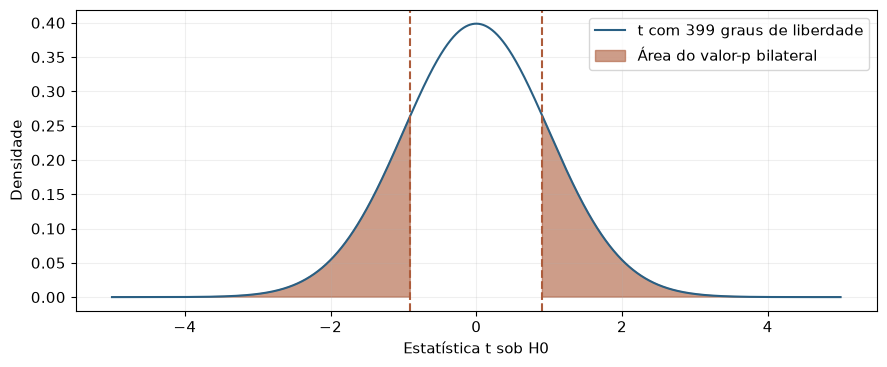

In [42]:
# Destaca as duas caudas que definem o valor-p bilateral.
eixo_t = np.linspace(-5, 5, 3001)
dens_t = stats.t.pdf(eixo_t, df=gl_t)
fig, ax = plt.subplots()
ax.plot(eixo_t, dens_t, color='#295f83', label=f't com {gl_t} graus de liberdade')
ax.fill_between(eixo_t, dens_t, where=(np.abs(eixo_t) >= abs(t_obs)), color='#ad5c3b', alpha=.6, label='Área do valor-p bilateral')
for ref in [-abs(t_obs), abs(t_obs)]:
    ax.axvline(ref, color='#ad5c3b', linestyle='--')
ax.set(xlabel='Estatística t sob H0', ylabel='Densidade')
ax.legend()
fig.tight_layout()
plt.show()

**Figura 20 - Caudas do teste bilateral para a renda média.** Com 399 graus de liberdade, as áreas além de ±0,907 somam valor-p de aproximadamente 0,365174. Fonte: CARUBBI, 2026.

#### 13.3.3. Interpretação

A média amostral observada é 3,135 SM, diferença de 0,135 SM para a referência. Obtivemos t ≈ 0,907 e valor-p bilateral de **0,365174**. Não rejeitamos a hipótese de média 3 SM ao nível de 5%, sem concluir que ela foi comprovada.

O IC bilateral aproximado de 95% da seção 10 contém 3 SM. Como usamos a mesma amostra, a mesma referência t e níveis compatíveis, intervalo e teste produzem decisões equivalentes.

A população simulada é assimétrica. O uso de n = 400 sustenta aqui uma inferência aproximada, sem tornar a distribuição t exata ou eliminar a necessidade de avaliar as condições do procedimento.

## 14. Estudo e exercícios

### 14.1. Materiais didáticos

Use as leituras para retomar os pontos em que houve dúvida:

| Tema | Leit. | Compl. |
|---|---|---|
| Seleção e planos amostrais | Barbetta, Reis e Bornia (2010), seção 2.2.1, p. 27-31 | Barbetta, Reis e Bornia (2010), seção 7.1, p. 169-172 |
| Distribuições amostrais e TCL | Barbetta, Reis e Bornia (2010), seções 7.1-7.2, p. 169-178 | (PINHEIRO et al., 2009), seção 6.1, exemplos 6.1-6.2, p. 156-159. Morettin e Bussab (2010), seção 10.8, p. 277-280 |
| Estimação e confiança | Barbetta, Reis e Bornia (2010), seção 7.3, p. 179-191 | Montgomery e Runger (2018), seções 8.2 e 8.4 |
| Testes de média e proporção | Barbetta, Reis e Bornia (2010), seções 8.1-8.8, p. 198-221 | Montgomery e Runger (2018), seções 9.3 e 9.5.1. (AMERICAN STATISTICAL ASSOCIATION, 2016), interpretação do valor-p |

**Tabela 18 - Leituras para retomada dos conteúdos das duas aulas.** Os recortes relacionam amostragem, distribuições amostrais, estimação e testes às referências de cada bloco. **Legenda.** Leit. = leitura principal. Compl. = leitura complementar. TCL = Teorema Central do Limite. p. = página ou páginas. Fonte: CARUBBI, 2026.

Para as funções computacionais, consulte os links junto às aplicações e as referências ao final. A leitura integral de todos os capítulos complementares não é necessária.

### 14.2. Leitura complementar opcional

**Poder do teste:** Barbetta, Reis e Bornia (2010), seção 8.10, p. 224-225. Ao ler, relacione a probabilidade de erro II à probabilidade de detectar uma alternativa especificada. Preserve a expressão “não rejeitar H0” ao interpretar as situações descritas na obra como “aceitar H0”.

Este conteúdo não será ministrado em sala nem cobrado nas avaliações e trabalhos. Não é necessário desenvolver os cálculos do exemplo ou o planejamento amostral dessa seção.

### 14.3. Exercícios indicados

Os exercícios abaixo foram selecionados de Barbetta, Reis e Bornia (2010) e ficam fora dos 200 minutos da agenda. Consulte os enunciados completos na obra.

| Tema | Loc. | Foco |
|---|---|---|
| Crítica de planos amostrais | Capítulo 2, exercício 7(a-e), p. 33 | Identificar fragilidades nos procedimentos de seleção e no alcance das conclusões |
| Distribuição amostral da média | Capítulo 7, exercício 2, p. 174 | Trabalhar com a população de quatro consumos de combustível, com seleção de tamanho dois e reposição |
| IC de proporção | Capítulo 7, exercício 10, p. 191 | Construir um intervalo de 95% com a amostra de 200 construções e proporção observada de 55% |
| IC de média | Capítulo 7, exercício 12, p. 191 | Usar os 36 resultados, média 98 e desvio-padrão 4, para estimar a média com 99% de confiança e discutir a referência 100 |
| Teste de proporção | Capítulo 8, exercício 15, p. 217 | Avaliar o resultado de 40 acertos em 60 questões de duas alternativas, ao nível de 5% |
| Teste t de média | Capítulo 8, exercício 19, p. 221 | Avaliar a duração dos pneus a partir da amostra de 20 unidades, ao nível de 1% |

**Tabela 19 - Exercícios indicados para estudo após as aulas.** A seleção reúne crítica de planos amostrais, distribuição da média, intervalos de confiança e testes para média e proporção. **Legenda.** Loc. = localização na obra. IC = intervalo de confiança. p. = página ou páginas. Fonte: Barbetta, Reis e Bornia (2010), capítulos 2, 7 e 8, nas páginas indicadas.

No exercício 12 do capítulo 7, siga a convenção desta aula para a variância populacional desconhecida: referência t com 35 graus de liberdade. Ao comparar com uma solução baseada em aproximação Normal, identifique a diferença entre os quantis usados.

## 15. Referências

1. AMERICAN STATISTICAL ASSOCIATION. *American Statistical Association releases statement on statistical significance and p-values*. Alexandria: ASA, 7 mar. 2016. [Declaração e princípios sobre valores-p](https://www.amstat.org/asa/files/pdfs/p-valuestatement.pdf). Acesso em: 12 nov. 2026.

2. BARBETTA, Pedro Alberto, REIS, Marcelo Menezes e BORNIA, Antonio Cezar. *Estatística para cursos de engenharia e informática*. 3. ed. São Paulo: Atlas, 2010. Seções 2.2.1, 7.1-7.3 e 8.1-8.8. Seção 8.10 como leitura complementar.

3. MONTGOMERY, Douglas C. e RUNGER, George C. *Applied Statistics and Probability for Engineers*. 7. ed. Hoboken: Wiley, 2018. Seções 7.2, 8.2, 8.4, 9.1, 9.3 e 9.5.1.

4. MORETTIN, Pedro Alberto e BUSSAB, Wilton de Oliveira. *Estatística básica*. 6. ed. São Paulo: Saraiva, 2010. Seção 10.8, p. 277-280.

5. NUMPY DEVELOPERS. *NumPy v2.5 manual*. 2026. [Generator.choice](https://numpy.org/doc/2.5/reference/random/generated/numpy.random.Generator.choice.html) e [rotinas estatísticas](https://numpy.org/doc/2.5/reference/routines.statistics.html). Acesso em: 12 nov. 2026.

6. PANDAS DEVELOPMENT TEAM. *pandas documentation*. 2026. [DataFrame.nsmallest](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.nsmallest.html) e [Series.mean](https://pandas.pydata.org/docs/reference/api/pandas.Series.mean.html). Acesso em: 12 nov. 2026.

7. PINHEIRO, João Ismael D., CUNHA, Sonia Baptista da, CARVAJAL, Santiago Ramírez e GOMES, Gastão Coelho. *Estatística básica: a arte de trabalhar com dados*. Rio de Janeiro: Elsevier, 2009. Seção 6.1, exemplos 6.1-6.2, p. 156-159.

8. SCIPY COMMUNITY. *SciPy v1.18.0 manual*. 2026. [Estatística](https://docs.scipy.org/doc/scipy/reference/stats.html), com verbetes norm, t, sem, binomtest e ttest_1samp. Acesso em: 12 nov. 2026.

9. STATSMODELS DEVELOPERS. *Statsmodels 0.14.6 documentation*. 2025. [proportion_confint](https://www.statsmodels.org/v0.14.6/generated/statsmodels.stats.proportion.proportion_confint.html) e [proportions_ztest](https://www.statsmodels.org/v0.14.6/generated/statsmodels.stats.proportion.proportions_ztest.html). Acesso em: 12 nov. 2026.